# Advanced-Tech Sector Portfolio Analysis

This is an End-to-end quantitative analysis of **35 stocks** across **AI, Semiconductor, and New Energy** sectors — from raw data through EDA, volatility, correlation, lead-lag, risk assessment, mean-variance portfolio optimization, and backtesting. By directing this analysis, I want to figure out the relationships between chips industry and AI industry; and testing if there is any correlations with New-Energy company.

> Data period: May 2025 – May 2026 (251 trading days)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Image
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

DATA = Path("data")
CHART = Path("charts")

## Results

| Portfolio Strategy | Total Return | Sharpe Ratio | Max Drawdown | Win Rate |
|---|:---:|:---:|:---:|:---:|
| **Max Sharpe** | **+364.8%** | **4.46** | -13.6% | 63.6% |
| Sector Equal Weight | +80.9% | 2.15 | -14.5% | 56.0% |
| Equal Weight | +75.6% | 2.03 | -15.1% | 56.4% |
| S&P 500 (Benchmark) | +26.8% | 1.63 | -9.1% | 57.2% |

> The optimized Max Sharpe portfolio delivered **13.6x** the S&P 500 return over the analysis period, driven by concentrated allocation to top Chip-sector names (INTC, MU, GOOGL each at the 15% cap).

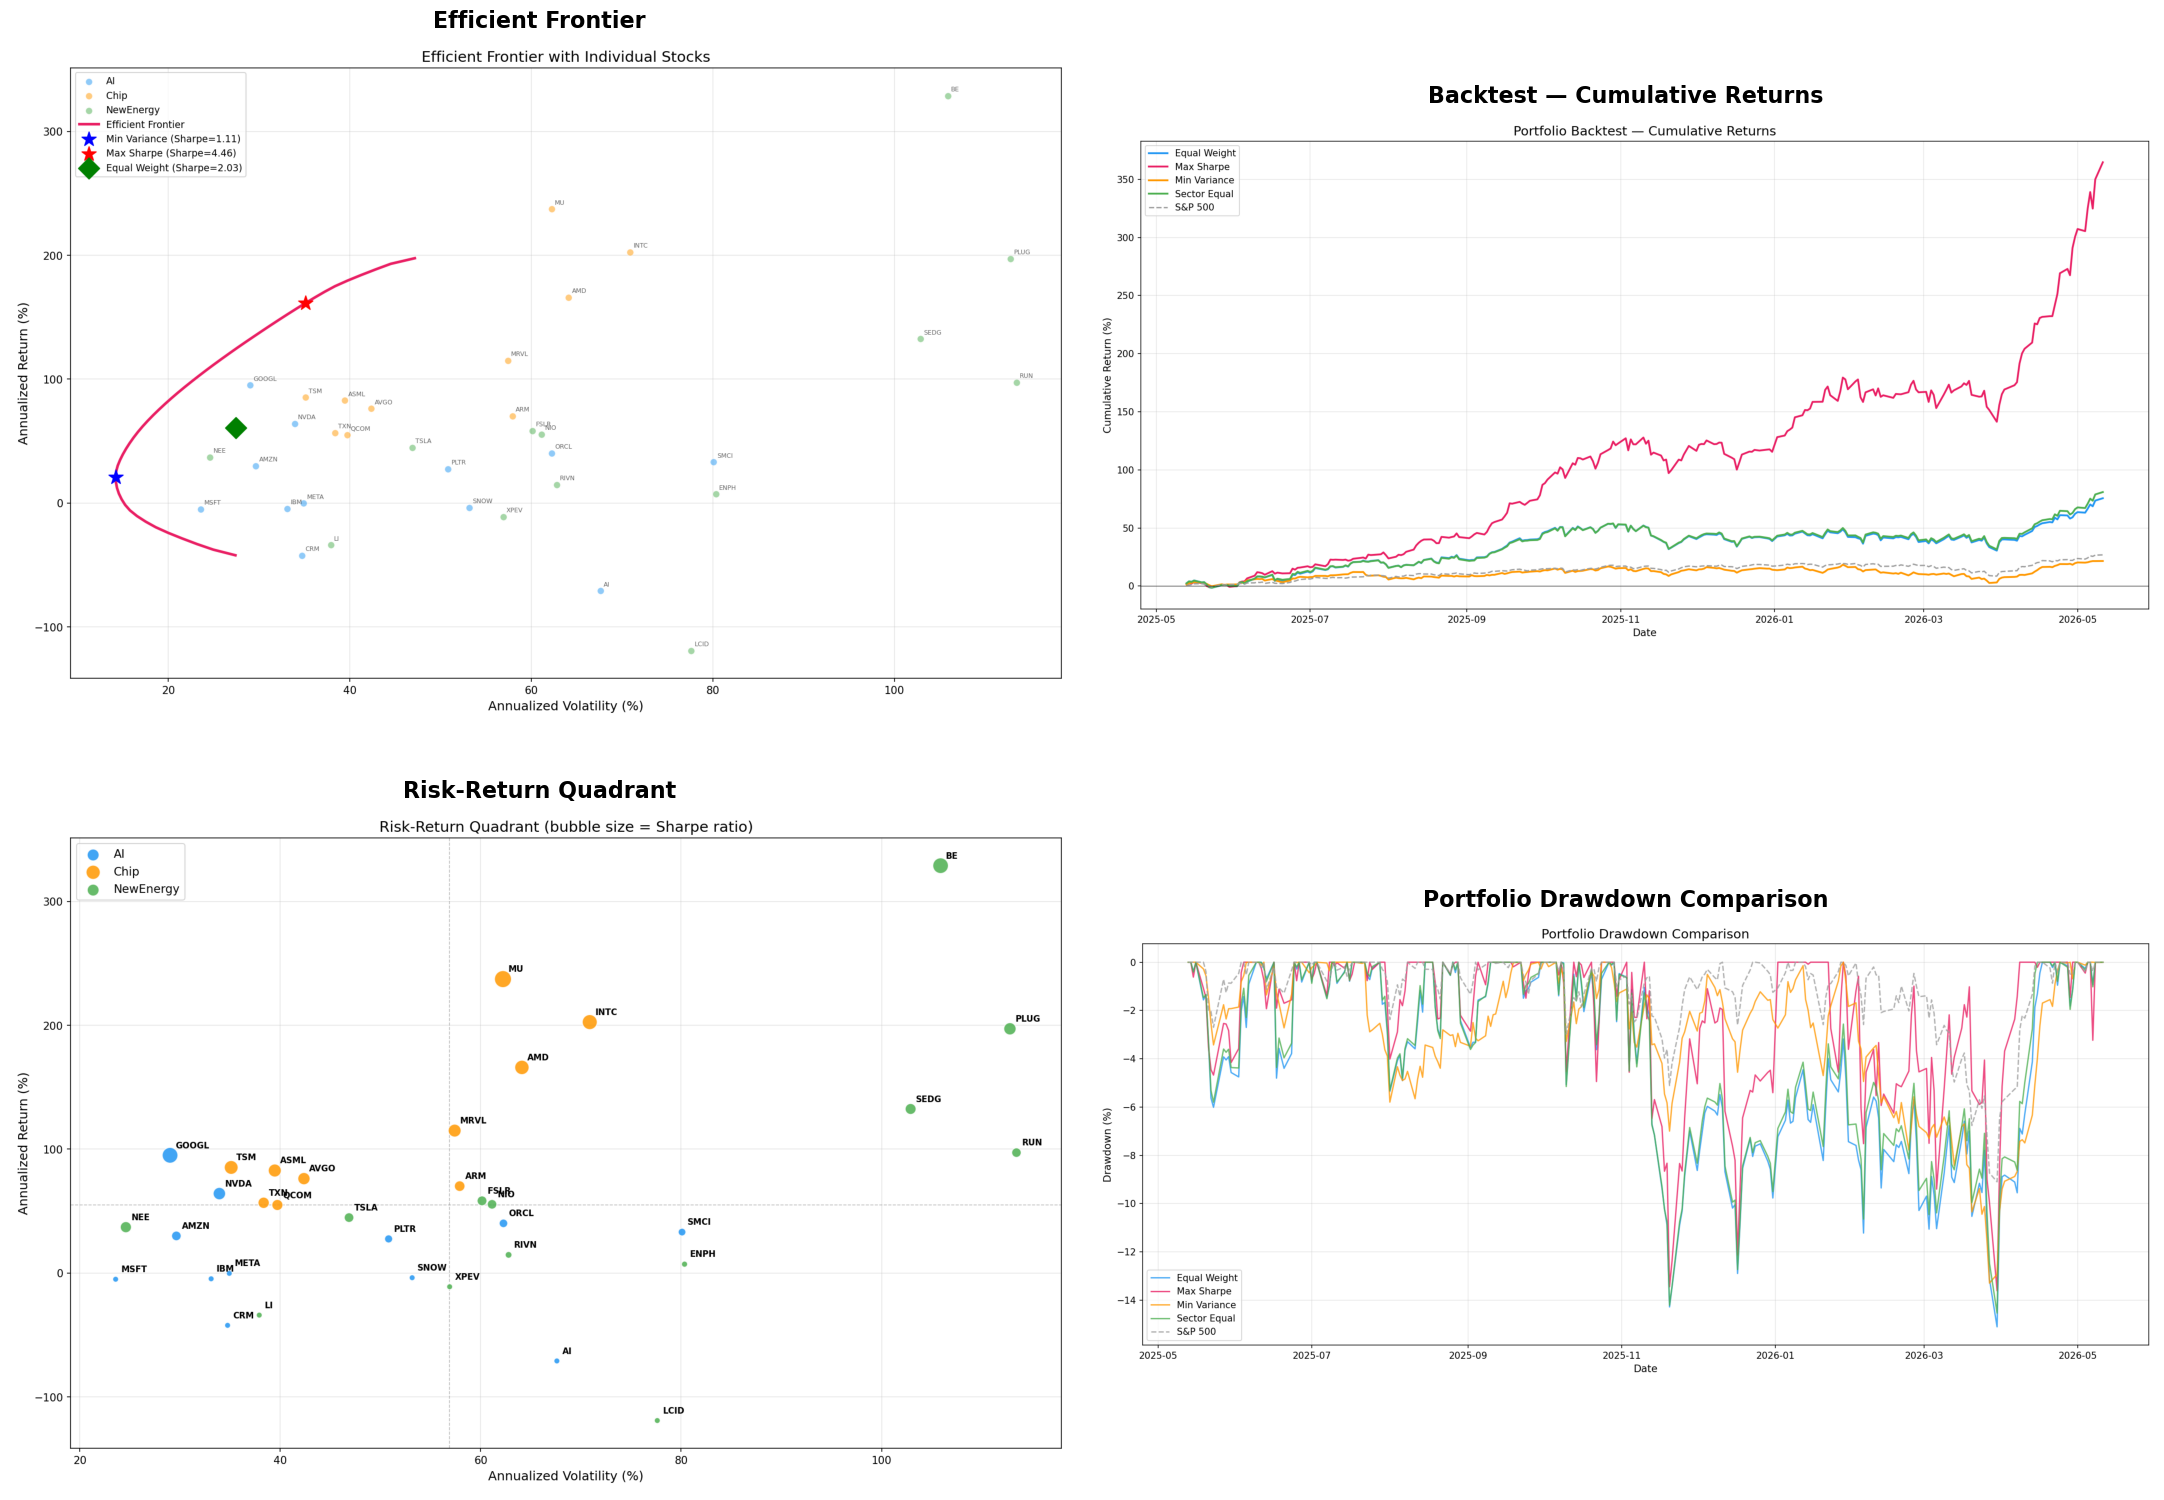

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(22, 16))
charts = [
    (CHART / "Part6_Portfolio/Step12_EfficientFrontier/efficient_frontier.png", "Efficient Frontier"),
    (CHART / "Part6_Portfolio/Step13_Backtest/cumulative_returns.png", "Backtest — Cumulative Returns"),
    (CHART / "Part5_Risk/Step11_RiskMetrics/risk_return_quadrant.png", "Risk-Return Quadrant"),
    (CHART / "Part6_Portfolio/Step13_Backtest/drawdown_comparison.png", "Portfolio Drawdown Comparison"),
]
for ax, (path, title) in zip(axes.flat, charts):
    ax.imshow(mpimg.imread(str(path)))
    ax.set_title(title, fontsize=16, fontweight="bold", pad=12)
    ax.axis("off")
plt.tight_layout(pad=2)
plt.show()

### Results(figures) Interpretation:

  1. **Efficient Frontier**: By optimizing the weight allocation across 35 stocks, the portfolio breaks through the
  risk-return limitations of individual stocks. The **Max Sharpe portfolio** (annualized return 161.5%, volatility 35.1%)
  and the **Min Variance portfolio** (annualized return 20.7%, volatility 14.2%) represent the two extremes of "best
  risk-adjusted return" and "lowest risk" respectively. All individual stocks fall below the efficient frontier curve,
  demonstrating that scientific weight allocation always outperforms single-stock bets.

  2. **Backtest — Cumulative Returns**: The **highest-return portfolio** (Max Sharpe) achieved +364.8% total return, exceeding
  the S&P 500's +26.8% by 13.6x, primarily driven by concentrated allocation in Chip-sector stocks. However, these
  results are derived from historical data and cannot perfectly predict future market performance.

  3. **Risk-Return Quadrant**: **GOOGL** and **TSM** in the upper-left quadrant (low volatility, high return) represent the optimal
  picks. **BE** and **PLUG** in the upper-right surged dramatically but with volatility exceeding 100%, making them high-risk
  bets. **SMCI** in the lower-right endured 80% volatility for only 33% return — the worst risk-reward tradeoff. Most AI
  blue-chips (**MSFT**, **META**) fall in the lower-left, underperforming the broader market.
  
  4. **Portfolio Drawdown Comparison**: The **Max Sharpe portfolio** not only delivered the highest returns but also had a
  shallower maximum drawdown (-13.6%) than the **Equal Weight portfolio** (-15.1%). This is somewhat counterintuitive —
  conventional wisdom suggests broad diversification reduces risk, yet concentrated holdings in quality stocks actually
  produced a smaller drawdown than spreading capital evenly. The Min Variance portfolio had the smallest drawdown
  (-13.3%) but at the cost of only +21.6% return, even underperforming the S&P 500 (+26.8%), which aligns with the
  classic principle that risk and return are inseparable.
  

---
## Analysis Pipeline

```
Data ── Part 1: EDA ── Part 2: Volatility ── Part 3: Correlation ── Part 4: Lead-Lag
                                                                       │
                        Part 6: Portfolio ◄── Part 5: Risk ◄───────────┘
```

| Part | Script | Steps | Description |
|---|---|:---:|---|
| Data | `download_data.py` | 1 | Download 1-year daily OHLCV from Yahoo Finance |
| Part 1: EDA | `EDA.py` `candlestick.py` `returns.py` | 2–3 | Data quality, line charts, return distributions |
| Part 2: Volatility | `volatility.py` | 4–5 | Annualized volatility, rolling volatility, anomaly detection |
| Part 3: Correlation | `correlation.py` | 6–7 | Cross-sector correlation, Beta analysis |
| Part 4: Lead-Lag | `leadlag.py` | 8–9 | Lagged correlation, leadership scores |
| Part 5: Risk | `risk.py` | 10–11 | Drawdowns, VaR, Sharpe / Sortino / Calmar |
| Part 6: Portfolio | `portfolio.py` | 12–13 | Efficient frontier, portfolio backtesting |

## Stocks Preference

In [4]:
summary = pd.read_csv(DATA / "_summary.csv")
overview = summary.groupby("Sector").agg(
    Count=("Ticker", "count"),
    Tickers=("Ticker", lambda x: ", ".join(x)),
)
display(overview)
print(f"\nData period: {summary['Start'].iloc[0]} ~ {summary['End'].iloc[0]}  |  {summary['Records'].iloc[0]} trading days per stock")

,Count,Tickers
Sector,,
AI,12,"NVDA, MSFT, GOOGL, META, AMZN, CRM, PLTR, AI, ..."
Chip,10,"AMD, INTC, TSM, AVGO, QCOM, TXN, MU, MRVL, ARM..."
Index,6,"^GSPC, ^IXIC, ^DJI, ^RUT, ^VIX, ^SOX"
NewEnergy,13,"TSLA, ENPH, SEDG, FSLR, RUN, PLUG, BE, NEE, RI..."



Data period: 2025-05-12 ~ 2026-05-11  |  251 trading days per stock


---
## Part 1: Exploratory Data Analysis

### Step 1 — Data Quality Check
(Use EDA.py)
All 9 quality checks passed. Only minor Yahoo data precision issues (NEE and XPEV each had 1 day where Open slightly exceeded High). VIX and SOX show zero volume throughout.

### Step 2 — Performance Ranking & Sector Comparison

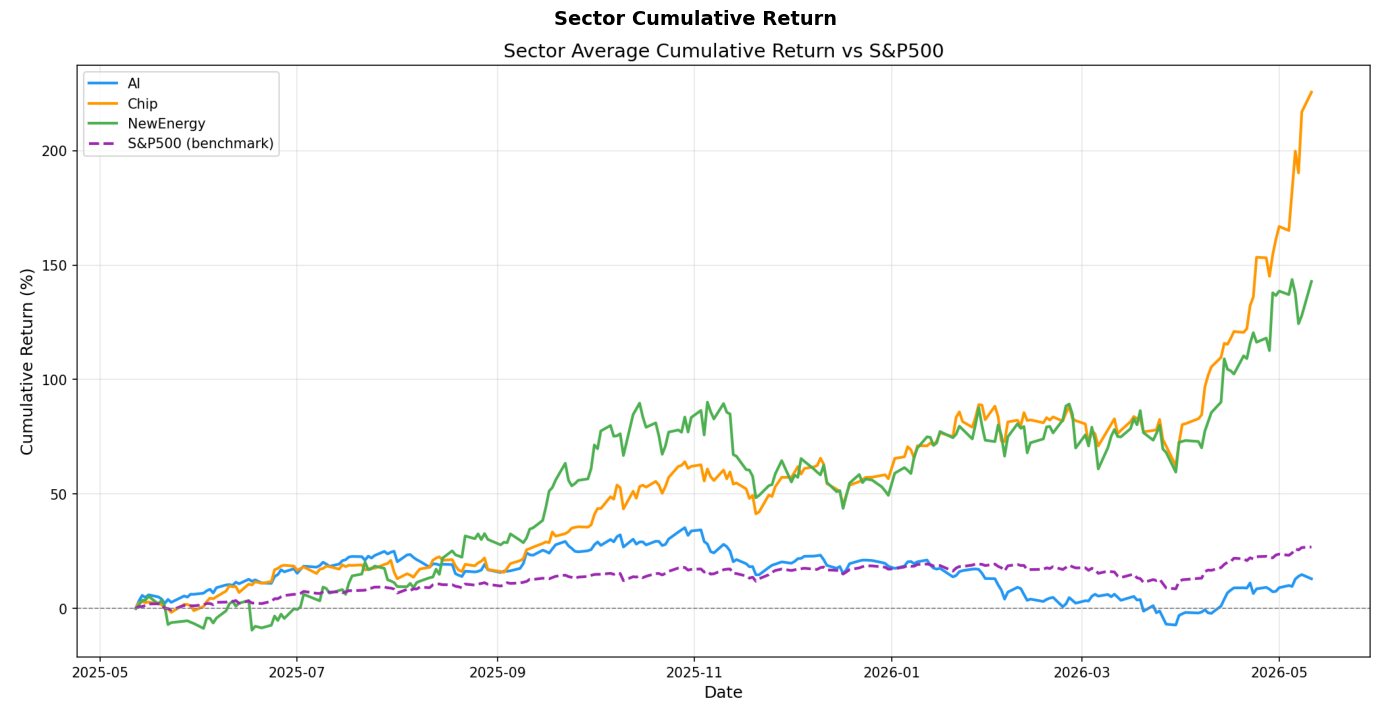

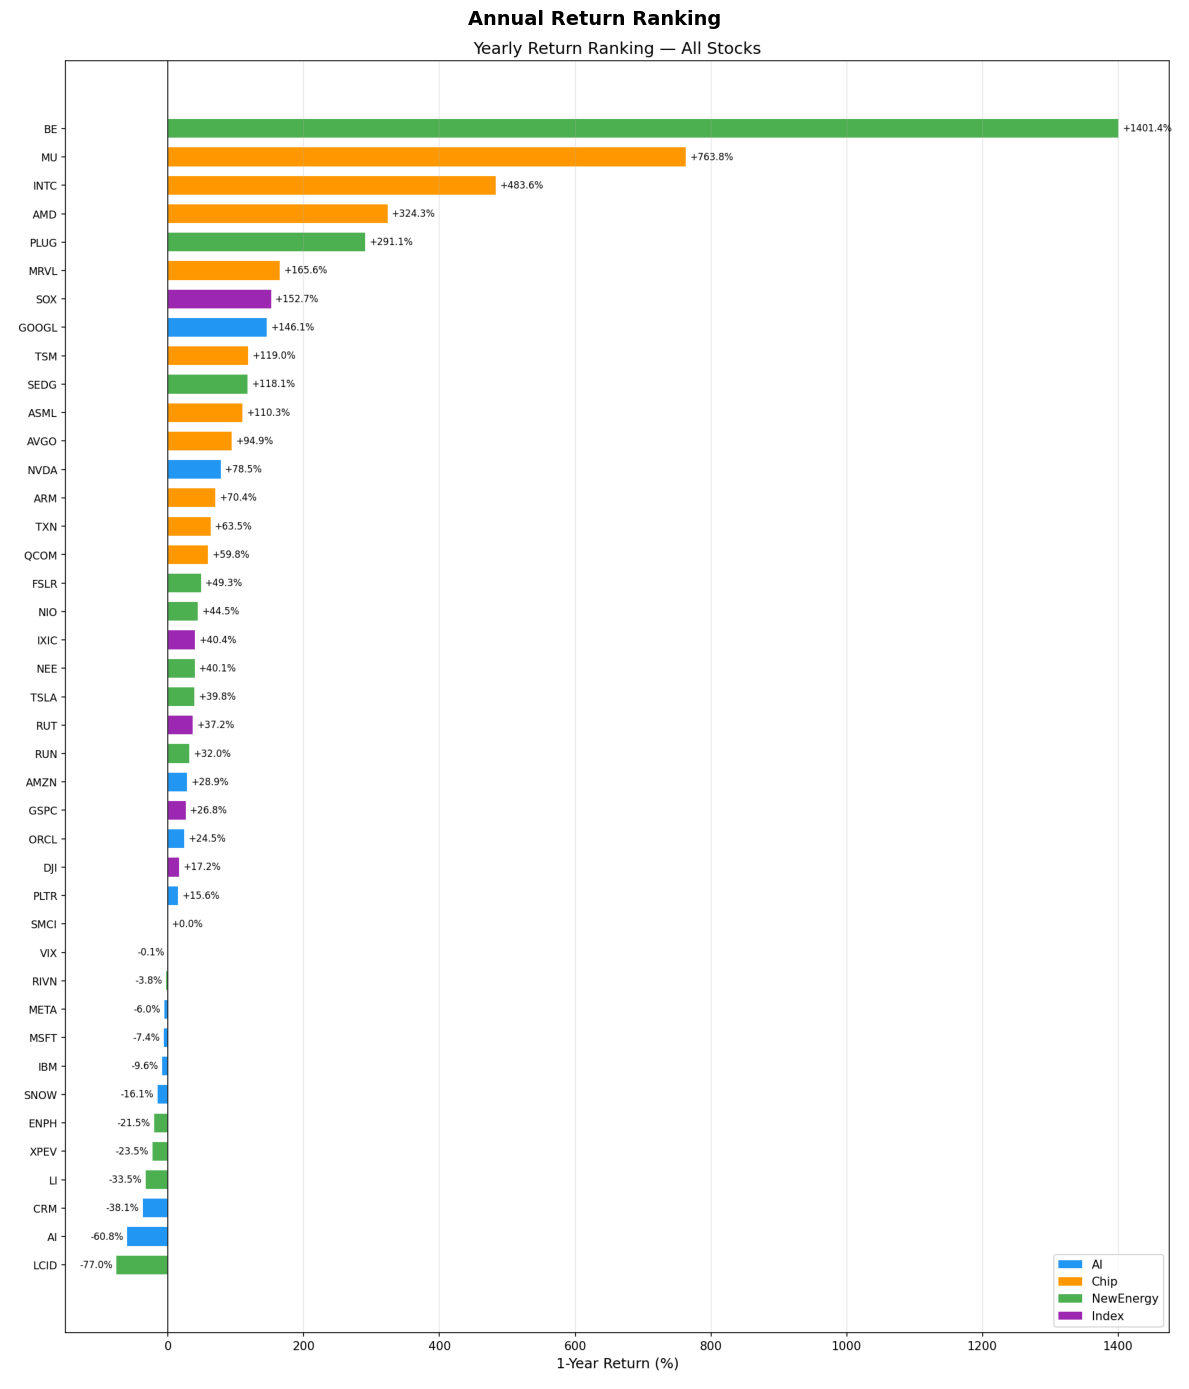

In [21]:
img1 = mpimg.imread(str(CHART / "Part1_EDA/Step2_LineCharts/sector_cumulative_return.png"))
img2 = mpimg.imread(str(CHART / "Part1_EDA/Step3_Returns/yearly_return_ranking.png"))

plt.figure(figsize=(14, 8))
plt.imshow(img1)
plt.title("Sector Cumulative Return", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 14)) 
plt.imshow(img2)
plt.title("Annual Return Ranking", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

<h3 align="center">FORMULA</h3>


1-Year Total Return： $$R = \left(\frac{P_{end}}{P_{start}} - 1\right) \times 100%$$
Sector Average Performance： $$\overline{X}{sector} = \frac{1}{n}\sum{i=1}^{n} X_i$$
Cumulative Return (Normalized): $$CR_t = \left(\frac{P_t}{P_0} - 1\right) \times 100%$$
Sector Average Cumulative Return: $$\overline{CR}t^{,sector} = \frac{1}{n}\sum{i=1}^{n} CR_t^{(i)}$$

  - $P_{end}$ — closing price on the last trading day
  - $P_{start}$ — closing price on the first trading day
  - $\overline{X}_{sector}$ — sector average of metric $X$ (e.g. return, volatility, Sharpe)
  - $n$ — number of stocks in the sector
  - $X_i$ — value of metric $X$ for the $i$-th stock
  - $CR_t$ — cumulative return at day $t$, normalized to the starting price
  - $P_t$ — closing price at day $t$
  - $P_0$ — closing price on day 0 (baseline)
  - $\overline{CR}_t^{\ sector}$ — sector average cumulative return at day $t$
  - $CR_t^{(i)}$ — cumulative return of the $i$-th stock at day $t$

In [ ]:
perf = pd.read_csv(CHART / "Part1_EDA/Step2_LineCharts/performance_summary.csv")

print("\u2501" * 60)
print("Top 10 winners")
print("\u2501" * 60)
display(perf.nlargest(10, "Return%")[["Ticker", "Name", "Sector", "Return%", "Annual_Vol%", "Sharpe", "Max_Drawdown%"]])

print("\n" + "\u2501" * 60)
print("Top 5 Losers")
print("\u2501" * 60)
display(perf.nsmallest(5, "Return%")[["Ticker", "Name", "Sector", "Return%", "Annual_Vol%", "Sharpe", "Max_Drawdown%"]])

print("\n" + "\u2501" * 60)
print("Sector Average Performance")
print("\u2501" * 60)
sector_avg = perf.groupby("Sector").agg({"Return%": "mean", "Annual_Vol%": "mean", "Sharpe": "mean", "Max_Drawdown%": "mean"}).round(2)
display(sector_avg.sort_values("Return%", ascending=False))

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Top 10 Gainers
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


,Ticker,Name,Sector,Return%,Annual_Vol%,Sharpe,Max_Drawdown%
28,BE,Bloom Energy,NewEnergy,1401.43,105.89,3.11,-45.94
18,MU,Micron,Chip,763.83,62.22,3.81,-30.28
13,INTC,Intel,Chip,483.59,70.88,2.86,-24.17
12,AMD,AMD,Chip,324.33,64.11,2.59,-27.76
27,PLUG,Plug Power,NewEnergy,291.11,112.81,1.75,-56.66
19,MRVL,Marvell,Chip,165.57,57.40,2.00,-26.37
40,^SOX,PHLX_Semiconductor,Index,152.69,32.72,3.02,-15.65
2,GOOGL,Google,AI,146.11,29.00,3.28,-20.37
14,TSM,TSMC,Chip,119.04,35.10,2.43,-18.14
24,SEDG,SolarEdge,NewEnergy,118.11,102.90,1.29,-37.26



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Top 5 Losers
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


,Ticker,Name,Sector,Return%,Annual_Vol%,Sharpe,Max_Drawdown%
31,LCID,Lucid,NewEnergy,-76.98,77.62,-1.53,-81.60
7,AI,C3.ai,AI,-60.83,67.60,-1.05,-73.39
5,CRM,Salesforce,AI,-38.09,34.74,-1.22,-42.92
33,LI,Li Auto,NewEnergy,-33.51,37.90,-0.90,-50.53
34,XPEV,XPeng,NewEnergy,-23.53,56.90,-0.19,-44.60



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Sector Average Performance
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


,Return%,Annual_Vol%,Sharpe,Max_Drawdown%
Sector,,,,
Chip,225.53,50.75,2.17,-27.74
NewEnergy,142.86,72.56,0.70,-44.47
Index,45.72,35.16,1.82,-18.03
AI,12.95,44.40,0.42,-41.12


### **Findings:**
1. **Chip sector dominates:** Average return +225.5%, Sharpe ratio 2.17
2. **AI software lags infrastructure:** AI sector averaged only +13.0%, below the S&P 500's +26.8%
3. **BE (Bloom Energy) surged 14x** over the year, from \$18.91 to \$283.92

The most surprising finding in this section is the exceptional stock performance of **Bloom Energy**. Bloom Energy significantly lifted the overall metrics of the New Energy sector. Without this company, the sector's average return would have been much weaker, even underperforming the broader market. After recalculation, the average return would be only around 38%.

Another notable observation is the overall performance of the **AI** sector. Both its return and Sharpe ratio reached only about one-third of the benchmark's level, which contrasts sharply with the strong market attention and enthusiasm surrounding the AI industry.
### Step 3 — Monthly Return Heatmap

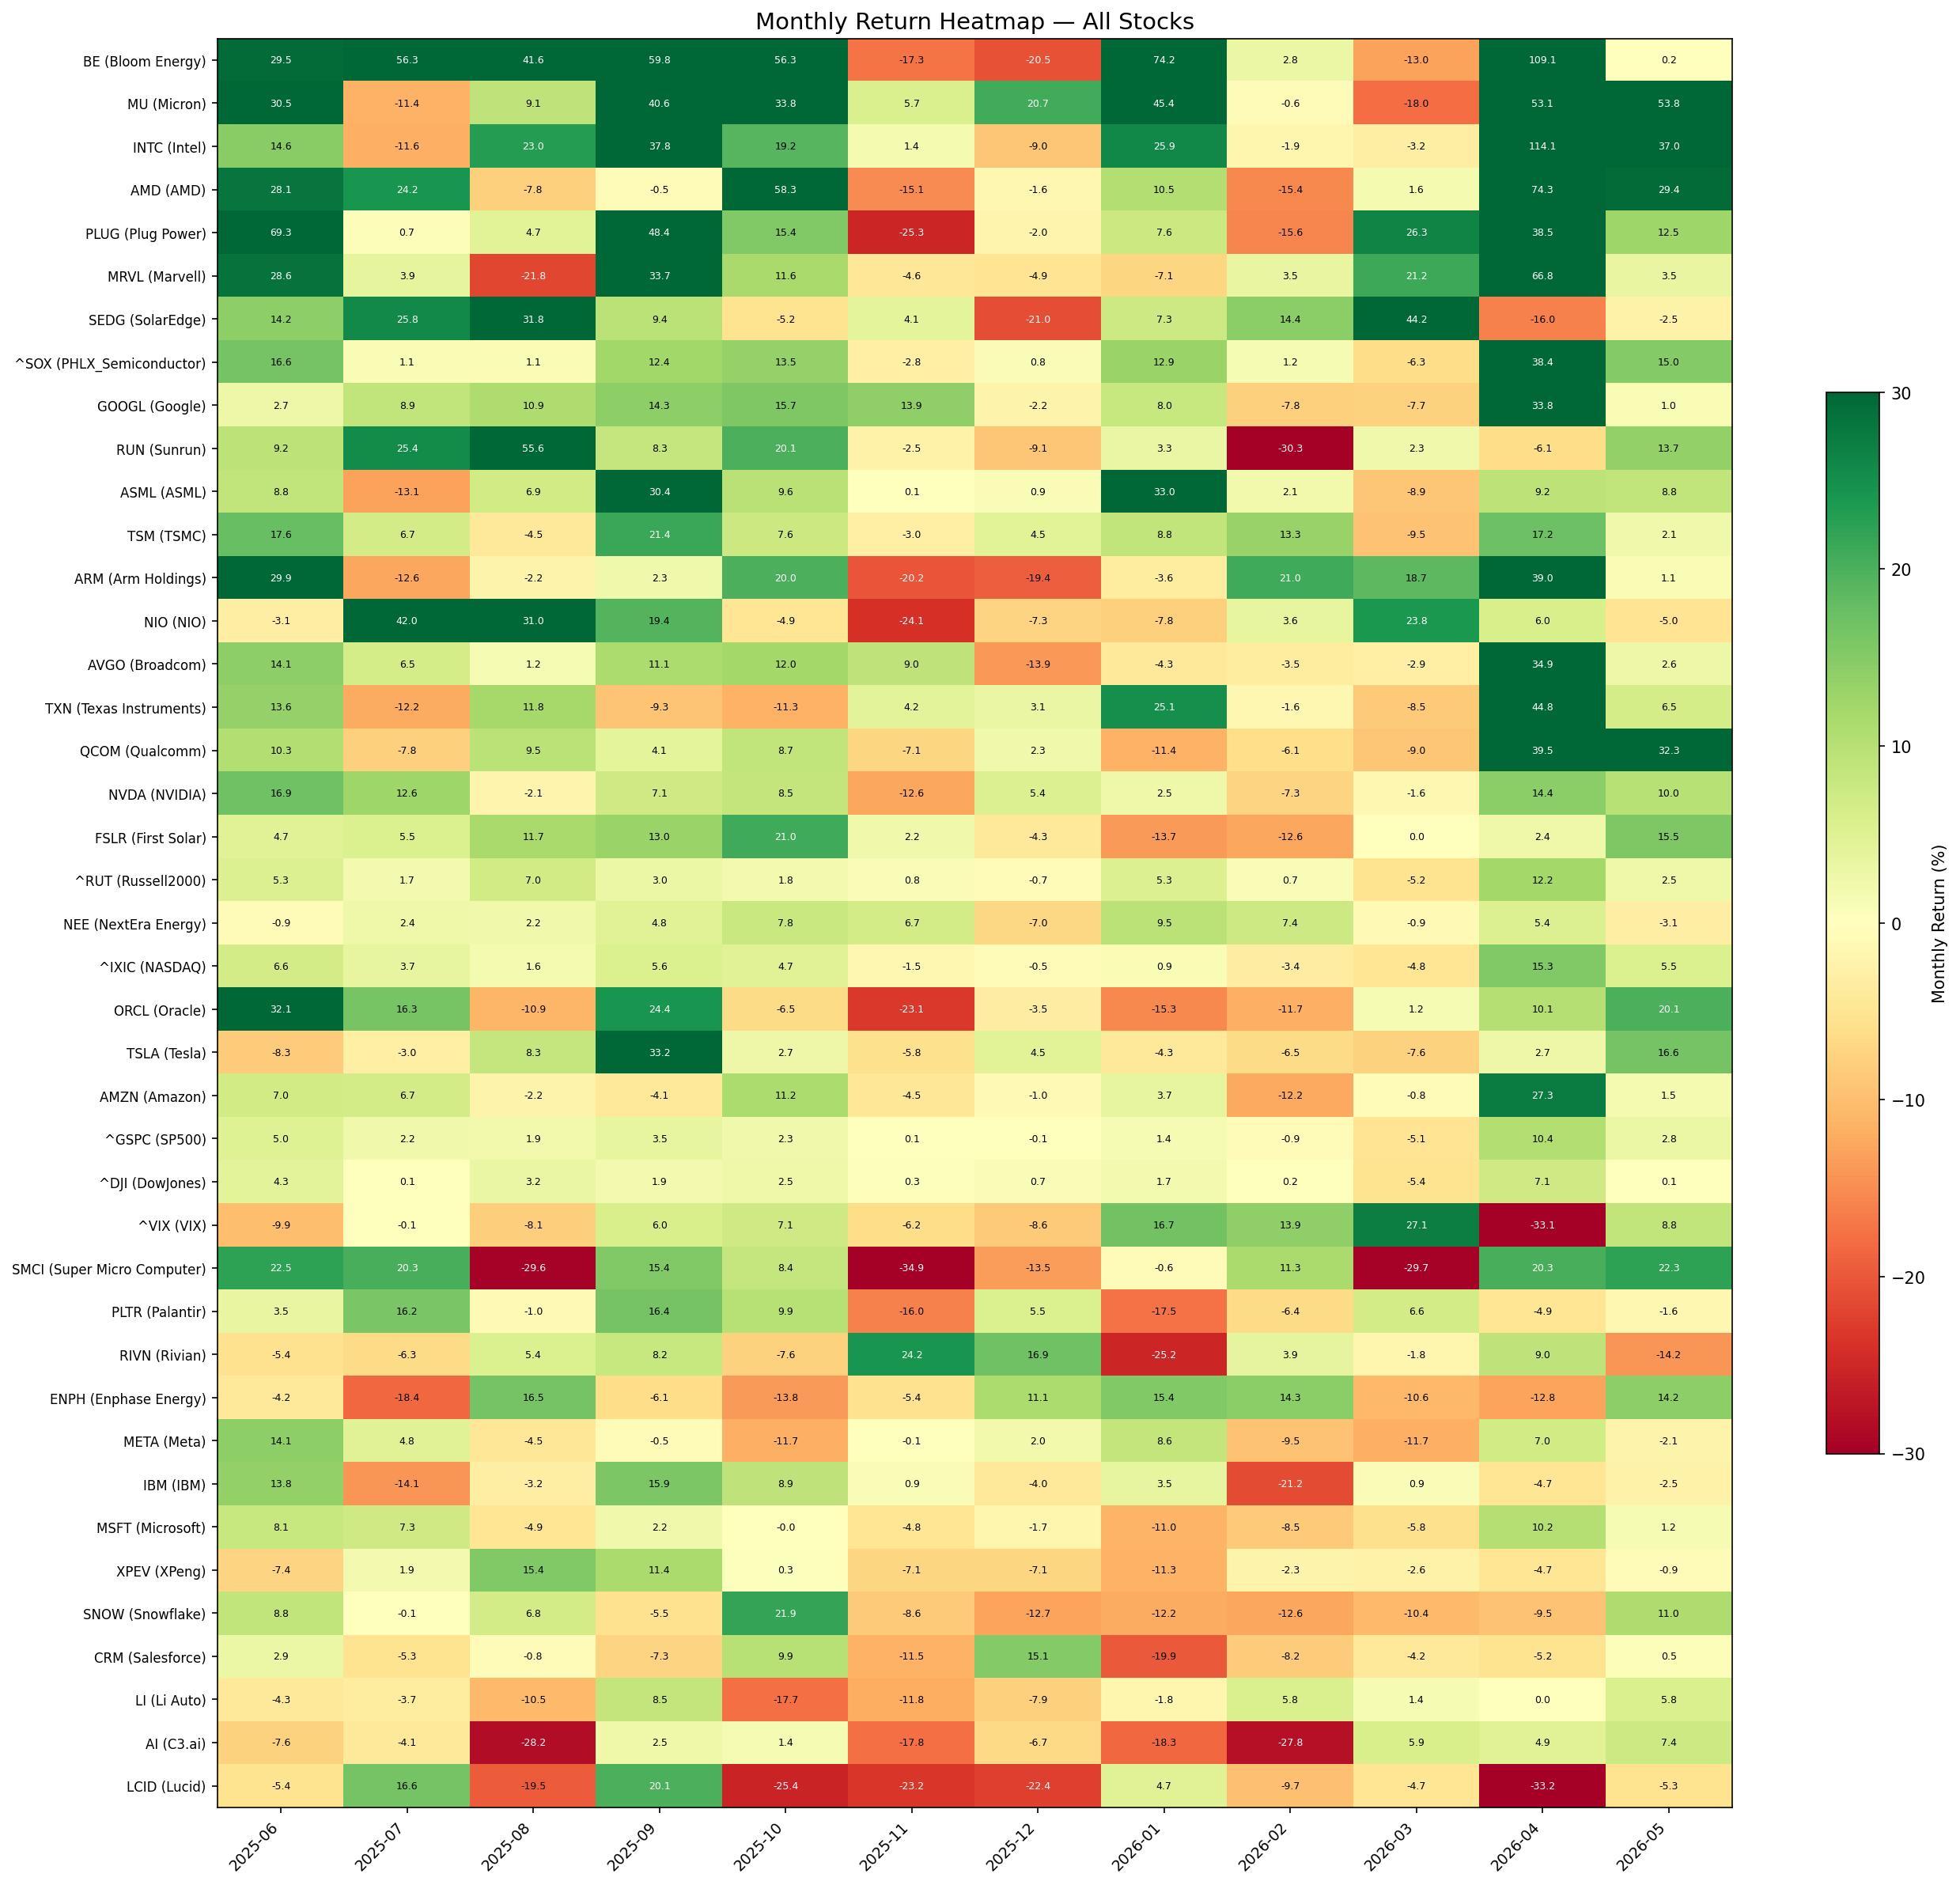

In [ ]:
display(Image(str(CHART / "Part1_EDA/Step3_Returns/monthly_return_heatmap.png"), width=900))

---
## Part 2: Volatility Analysis

### Cross-Sector Correlation with Decision

Average pairwise correlation at the individual stock level: AI vs Chip = 0.21, AI vs NewEnergy = 0.12, Chip vs NewEnergy = 0.18.

**Decision:** NewEnergy was excluded from the volatility comparison due to correlation below the threshold. AI and Chip show significantly stronger co-movement.

### Step 4 — Annualized Volatility & Step 5 — Rolling Volatility

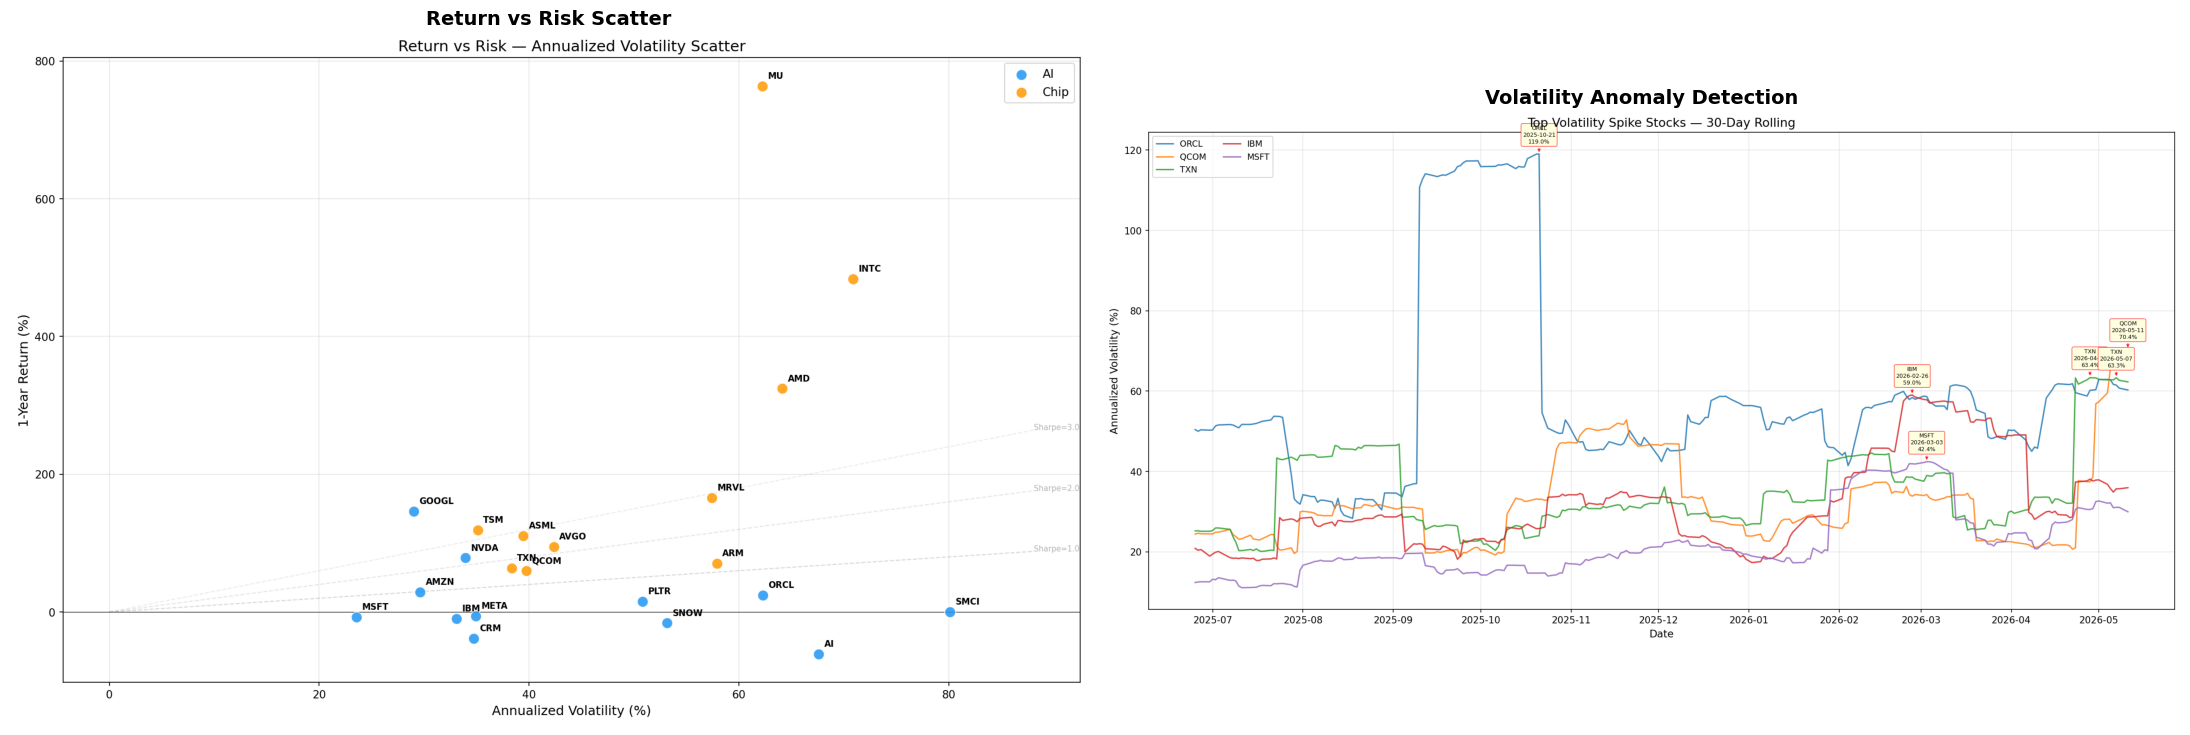

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))
ax1.imshow(mpimg.imread(str(CHART / "Part2_Volatility/Step4_AnnualizedVol/return_vs_risk_scatter.png")))
ax1.set_title("Return vs Risk Scatter", fontsize=14, fontweight="bold")
ax1.axis("off")
ax2.imshow(mpimg.imread(str(CHART / "Part2_Volatility/Step5_RollingVol/volatility_spike_highlight.png")))
ax2.set_title("Volatility Anomaly Detection", fontsize=14, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

### <center> **Formula**

**Annualized Volatility**: $$\sigma_{annual} = \sigma_{daily} \times \sqrt{252}$$ 
The $\sqrt{252}$ comes from the assumption that daily returns areindependent 

**Maximum Drawdown**: $$MDD = \min_{t}\left(\frac{P_t}{\displaystyle\max_{\tau \leq t},P_\tau} - 1\right) \times 100%$$

**Sharpe Ratio**: $$Sharpe = \frac{\bar{r}}{\sigma_{daily}} \times \sqrt{252}$$

**30-Day Rolling Volatility (Annualized)**: $$\sigma_{rolling,t} = \text{std}(r_{t-29},, r_{t-28},, \dots,, r_t) \times \sqrt{252} \times 100$$
**Median Rolling Volatility**: $$\tilde{\sigma} = \text{median}\left(\sigma_{rolling,t}\right) \quad \text{for all } t$$


  - $252$ — number of trading days per year
  - $P_t$ — closing price at day $t$
  - $\max_{\tau \leq t} P_\tau$ — highest closing price from the start up to day $t$
  - $\bar{r}$ — mean daily return
  - $r_{t-29}, r_{t-28}, \dots, r_t$ — daily returns over the trailing 30-day window ending at day $t$

### **Most important volatility events:**

| Ticker | Period | Peak Volatility | Catalyst |
|---|---|:---:|---|
| ORCL | Sep–Oct 2025 | 119.0% | \$300B OpenAI cloud deal surge followed by earnings miss|
| QCOM | May 2026 | 70.4% | Earnings beat + US-China tariff pause + AI phone chip news |
| IBM | Feb–Mar 2026 | 59.0% | Single-day -13.15%, Anthropic COBOL disruption narrative |
| MSFT | Feb–Mar 2026 | 42.4% | Worst quarter since 2008, \$357B market cap erased in a day |

#### **It is particularly interesting that both the Microsoft and Oracle events are connected to OpenAI**:

For Oracle's volatility, the main driver was its sharp stock price surge after signing a $300B cloud computing agreement with OpenAI, followed by a steep decline after its earnings report came in below expectations. Within 42 days, Oracle's volatility increased to 119%, while the stock recorded a total decline of -16% during the same period.

The cloud computing agreement between OpenAI and Oracle also affected Microsoft's stock performance around January of this year. Even though Microsoft's annual report showed strong results, it could not fully offset concerns about the company's setbacks in AI investment. The video on youtube of Yahoo Finance really explained this: https://www.youtube.com/watch?v=f2F8iDFZae8


---
## **Part 3: Correlation Analysis**

### **Step 6 — AI & Chip Correlation**

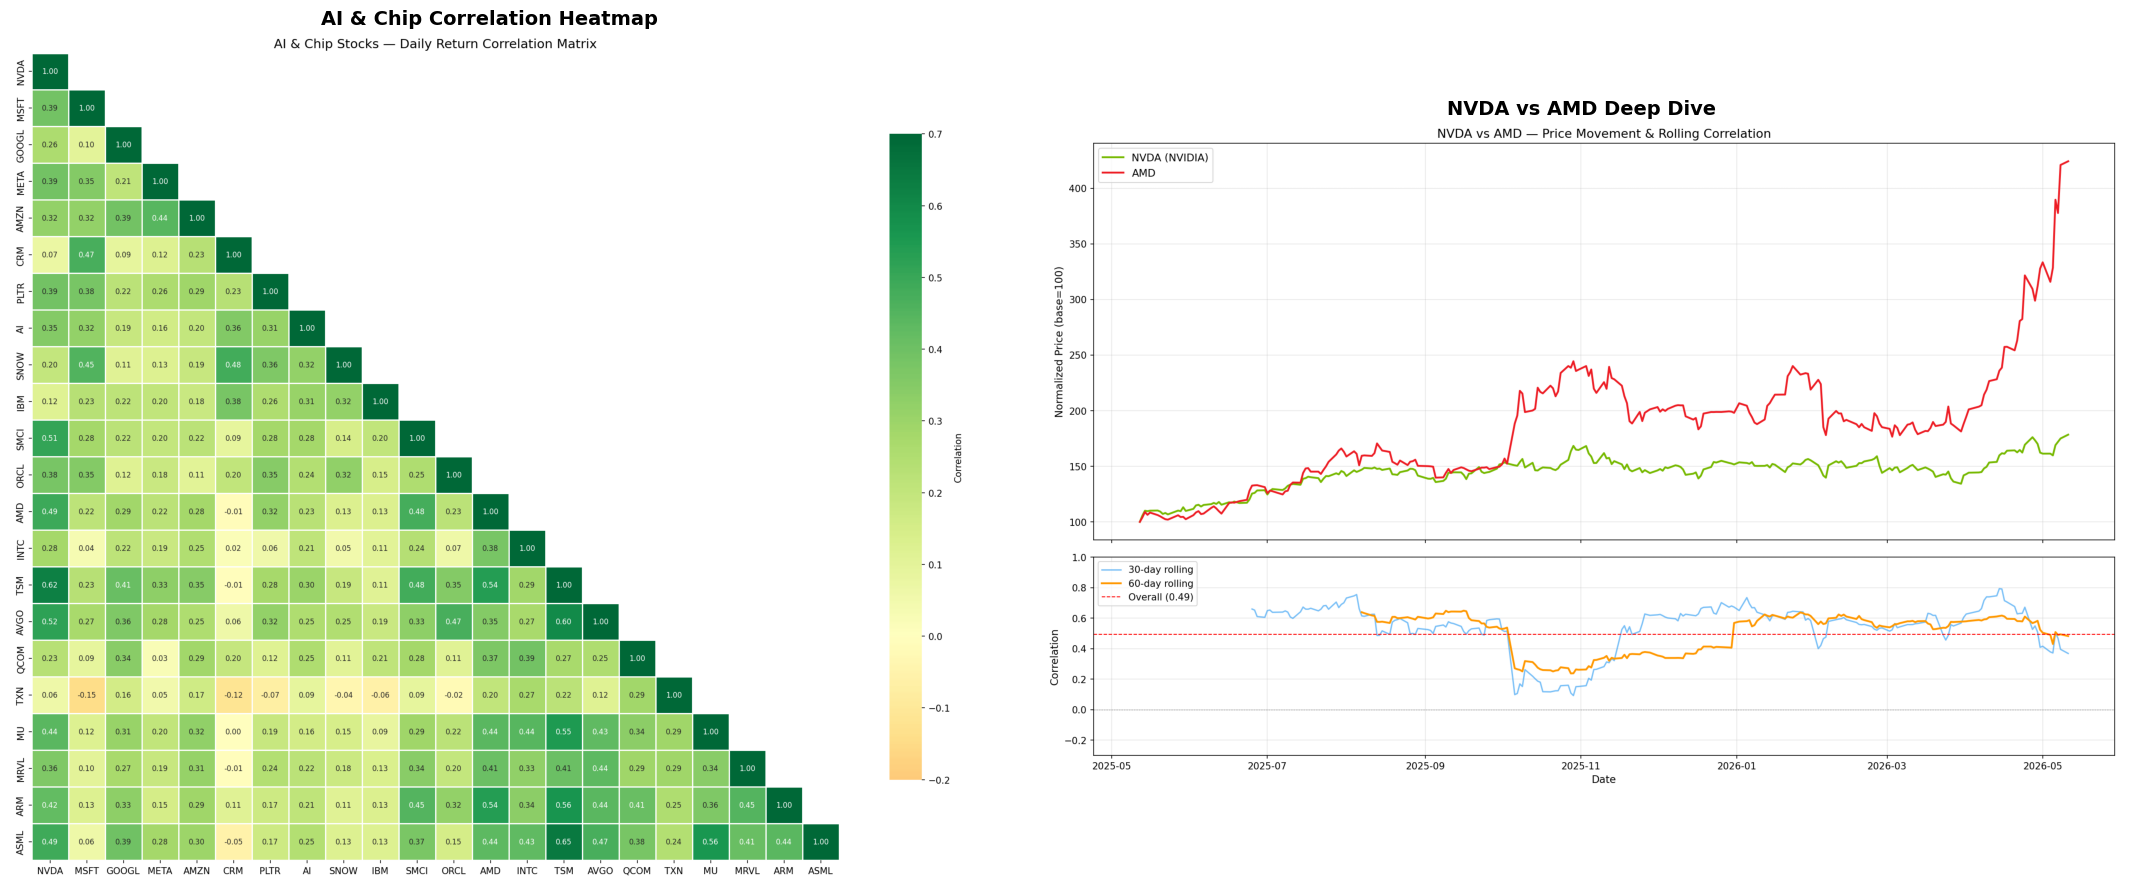

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
ax1.imshow(mpimg.imread(str(CHART / "Part3_Correlation/Step6_AIChipCorrelation/correlation_heatmap_ai_chip.png")))
ax1.set_title("AI & Chip Correlation Heatmap", fontsize=14, fontweight="bold")
ax1.axis("off")
ax2.imshow(mpimg.imread(str(CHART / "Part3_Correlation/Step6_AIChipCorrelation/nvda_vs_amd.png")))
ax2.set_title("NVDA vs AMD Deep Dive", fontsize=14, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

### <center> **Formula**

**Pearson Correlation Coefficient:**

Range is $[-1, 1]$: +1 means they move perfectly together, -1 means perfectly opposite, 0 means no linear relationship
  $$\rho_{A,B} = \frac{\displaystyle\sum_{t=1}^{N}(r_t^A - \bar{r}^A)(r_t^B -
  \bar{r}^B)}{\sqrt{\displaystyle\sum_{t=1}^{N}(r_t^A - \bar{r}^A)^2};\sqrt{\displaystyle\sum_{t=1}^{N}(r_t^B -
  \bar{r}^B)^2}}$$

**Normalized Price (Base = 100):** $$\hat{P}_t = \frac{P_t}{P_0} \times 100$$
**Linear Regression (OLS)**:

$$r_t^{AMD} = \beta \cdot r_t^{NVDA} + \alpha + \epsilon_t$$
**Rolling Correlation (30-day and 60-day)**:

This formula uses same pearson formula, but applied to a sliding window on the second graph.

  $$\rho_{A,B}^{(w,t)} = \text{Pearson}\left(r_{t-w+1}^A, \dots, r_t^A ;;; r_{t-w+1}^B, \dots, r_t^B\right)$$

  - $r_t^A$ — daily return of stock A at day $t$
  - $r_t^B$ — daily return of stock B at day $t$
  - $\bar{r}^A$ — mean daily return of stock A
  - $\bar{r}^B$ — mean daily return of stock B
  - $N$ — total number of trading days
  - $P_t$ — closing price at day $t$
  - $P_0$ — closing price on the first day
  - $r_t^{NVDA}$ — daily return of NVDA at day $t$
  - $\beta$ — slope (sensitivity of AMD's return to NVDA's return)
  - $\alpha$ — intercept (AMD's average return independent of NVDA)
  - $\epsilon_t$ — residual error at day $t$ (unexplained portion)
  - $w$ — window size in days (30 or 60)


### Findings:
1. **TSM is the correlation hub**  
   7 stocks show correlations above 0.45 with TSM, including **ASML (0.65)**, **NVDA (0.62)**, and **AVGO (0.60)**.  
   >As the foundry for nearly all major chip companies, TSM's stock price essentially reflects demand across the broader semiconductor industry.

2. **NVDA and AMD are competitors, but not interchangeable**  
   Their correlation is **0.49**, with same-direction trading days of **68.4%**.

   > Although AMD and Nvidia are both chip companies, their correlation suggests that they now occupy very different positions in the market. AMD appears more closely associated with **gaming-related chips**, while Nvidia is more strongly positioned in **AI computing chips**, especially those used for model training and high-performance AI workloads.

3. **TXN is the outlier**  
   TXN is negatively correlated with several AI stocks, suggesting that it is relatively independent from the broader tech/AI ecosystem.
    >It is naturally a useful tool for risk diversification?
### **Step 7 — Beta Analysis (vs S&P 500)**

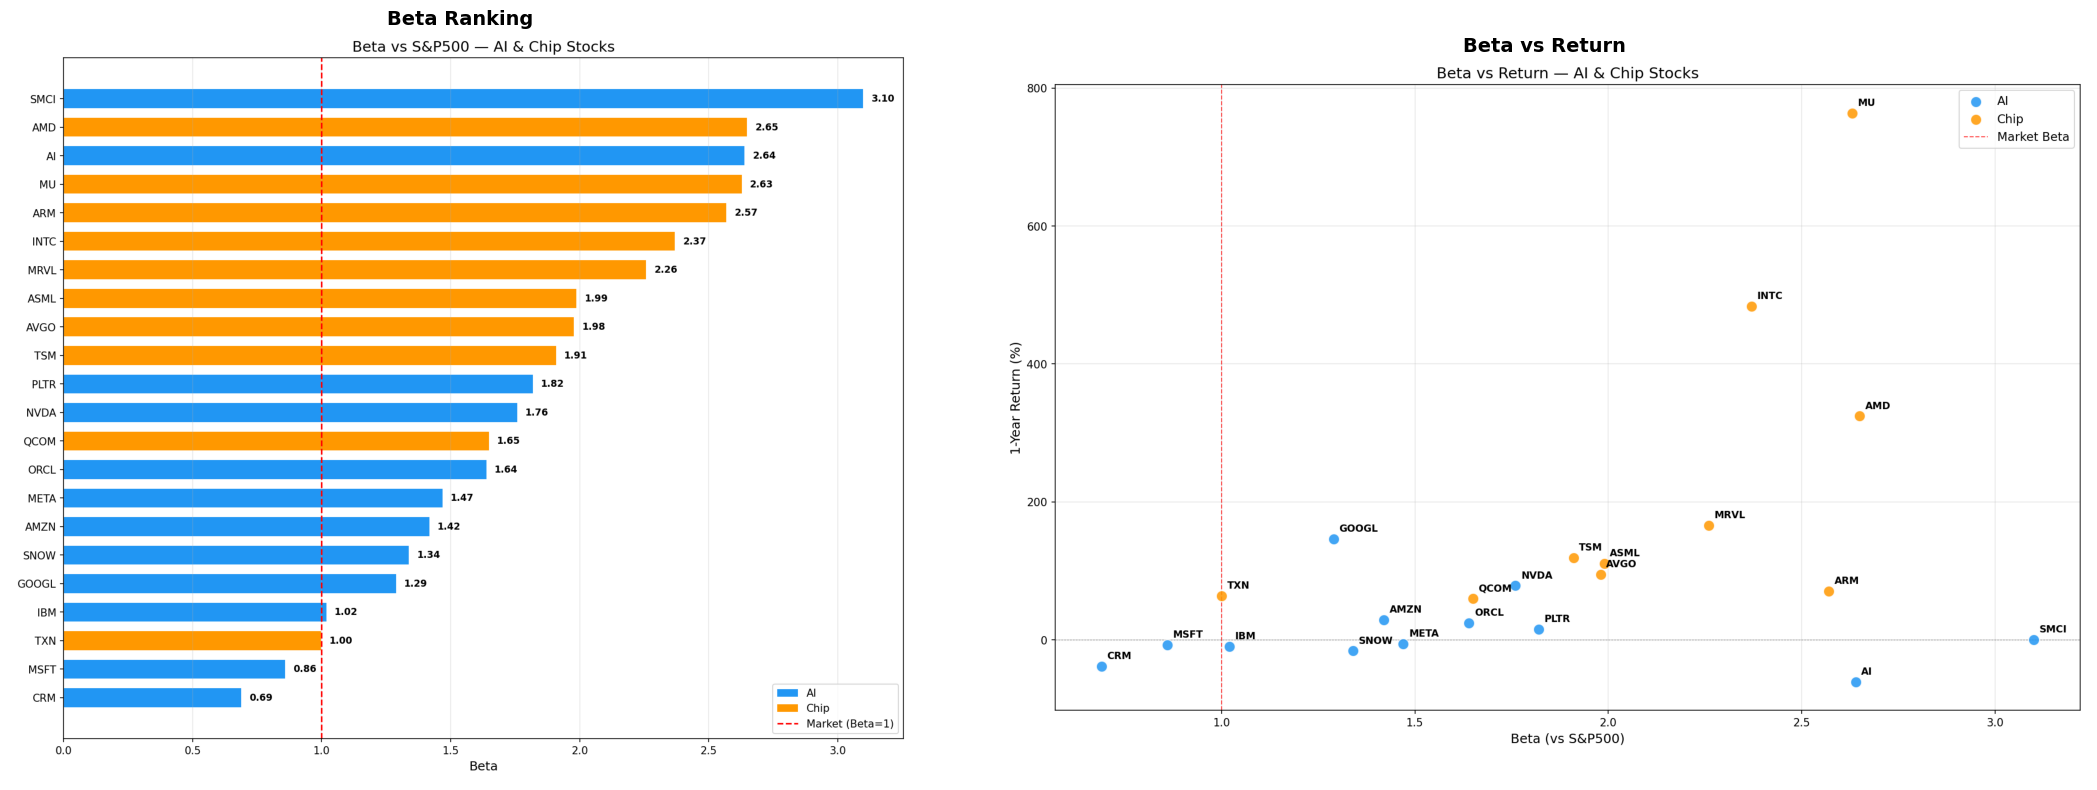

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))
ax1.imshow(mpimg.imread(str(CHART / "Part3_Correlation/Step7_Beta/beta_ranking.png")))
ax1.set_title("Beta Ranking", fontsize=14, fontweight="bold")
ax1.axis("off")
ax2.imshow(mpimg.imread(str(CHART / "Part3_Correlation/Step7_Beta/beta_vs_return.png")))
ax2.set_title("Beta vs Return", fontsize=14, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

<h3 align="center">FORMULA</h4> 
Here, **Beta** represents sensitivity to market fluctuations, while **Alpha** represents the excess return generated by an individual stock itself after removing the effect of broader market movements.

$$\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}$$
$$\alpha_i = (R_i - R_f) - \beta_i \cdot (R_m - R_f)$$

  - $\text{Cov}(R_i, R_m)$ — covariance between stock $i$'s return and market return
  - $\text{Var}(R_m)$ — variance of market return (S&P 500)
  - $R_i$ — annualized return of stock $i$
  - $R_m$ — annualized market return (S&P 500)
  - $R_f$ — risk-free rate (5%)
### Findings:
1. **High Beta ≠ High Return:** SMCI (Beta 3.10) returned 0%, while GOOGL (Beta 1.29) returned +146%. Seek positive Alpha, not just high Beta.

2. **Alpha is the key metric**: Alpha measures **excess return after removing market effects**. The chip sector has an average Alpha of **+62.8%**, indicating that it systematically outperformed the market. In contrast, the AI sector has an average Alpha of **-24.2%**, meaning that even after accounting for market fluctuations, AI stocks still generated negative excess returns.


---
## **Part 4: Lead-Lag Analysis**

### **Step 8 — Lagged Correlation & Step 9 — Leadership Scores**

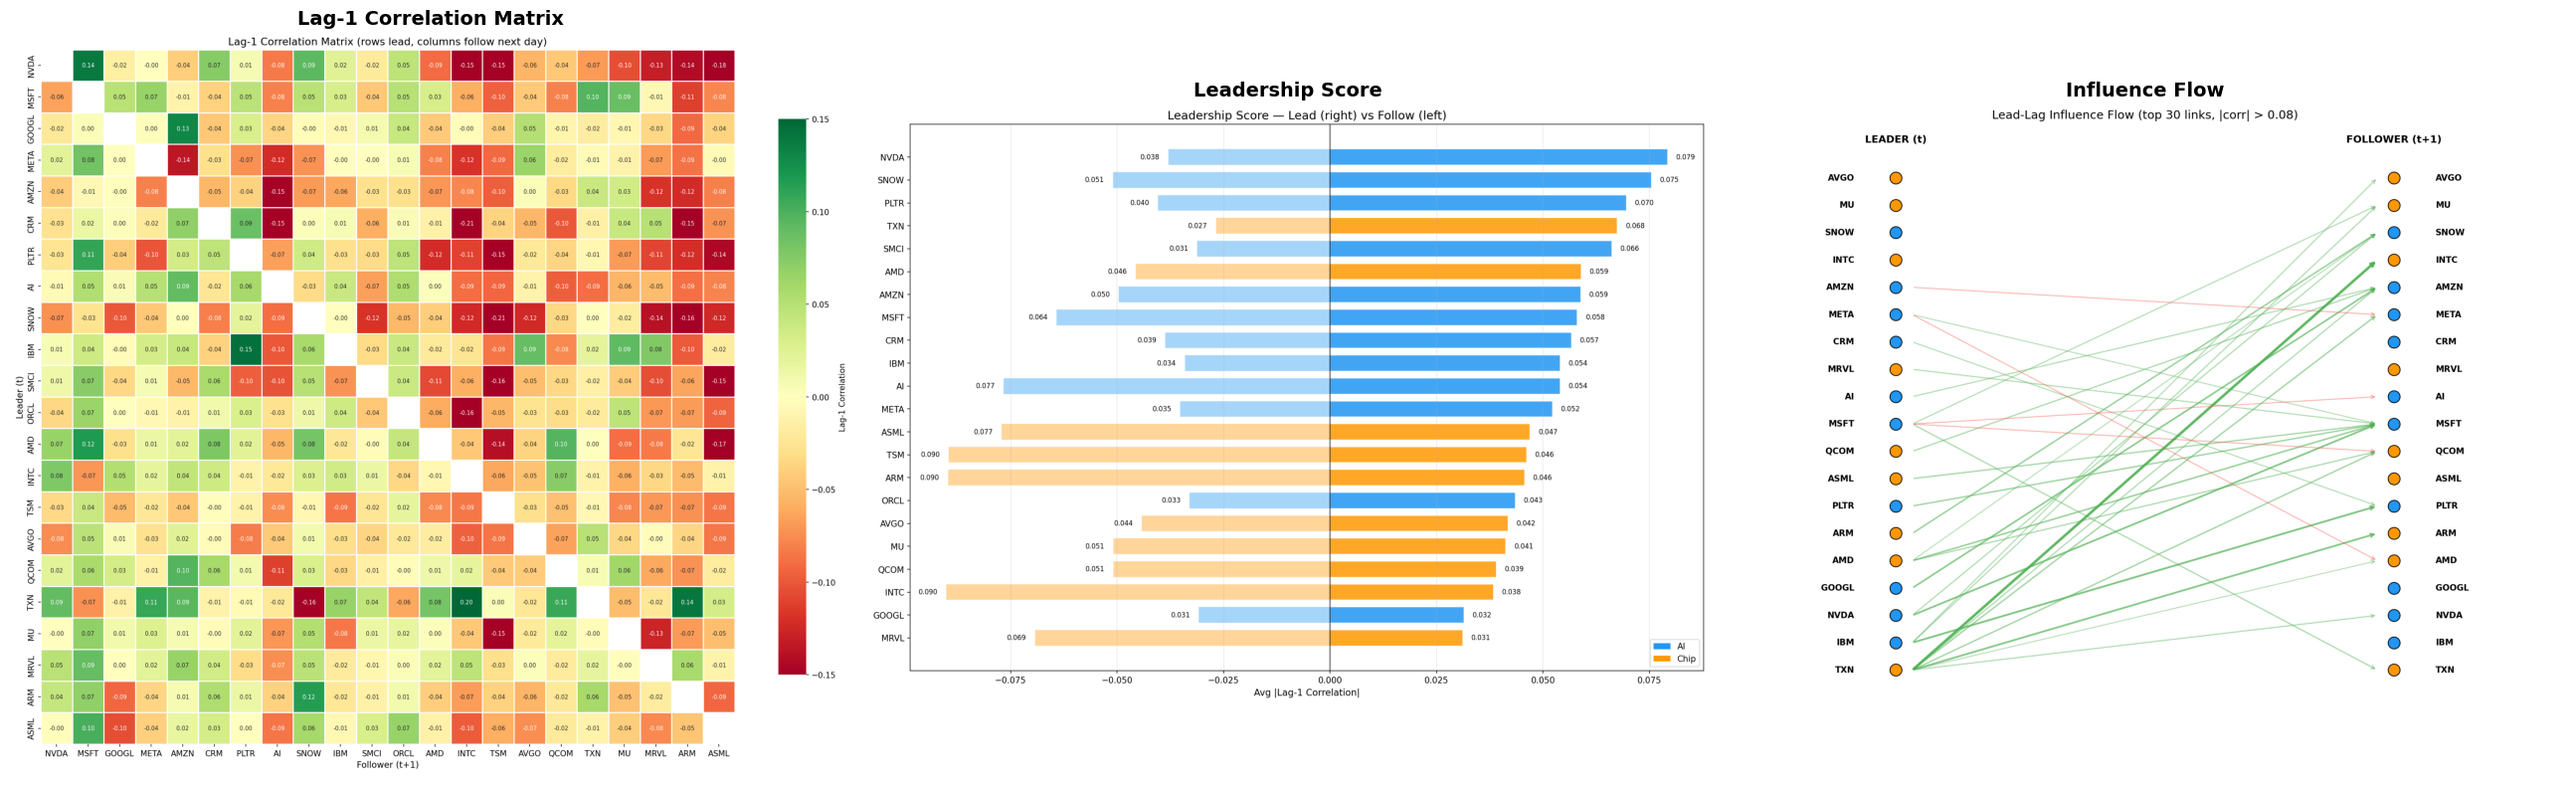

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(26, 8))
imgs = [
    (CHART / "Part4_LeadLag/Step8_LaggedCorrelation/lag1_heatmap.png", "Lag-1 Correlation Matrix"),
    (CHART / "Part4_LeadLag/Step9_Leadership/leadership_score.png", "Leadership Score"),
    (CHART / "Part4_LeadLag/Step9_Leadership/influence_flow.png", "Influence Flow"),
]
for ax, (path, title) in zip(axes, imgs):
    ax.imshow(mpimg.imread(str(path)))
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

<h3 align="center">FORMULA</h4> 

**Lagged Correlation**:
$$\rho_{A \to B}^{(k)} = \text{Pearson}\left(r_t^A,; r_{t+k}^B\right)$$
**Lag-1 Correlation Matrix**
$$M_{ij} = \rho_{i \to j}^{(1)}$$
**Average Lead Strength**
$$S_{lead}^{(i)} = \frac{1}{N-1}\sum_{j \neq i} \left|\rho_{i \to j}^{(1)}\right|$$
**Average Follow Strength**:
$$S_{follow}^{(i)} = \frac{1}{N-1}\sum_{j \neq i} \left|\rho_{j \to i}^{(1)}\right|$$
**Lead Ratio**:
$$LR^{(i)} = \frac{S_{lead}^{(i)}}{S_{follow}^{(i)}}$$
  - $r_t^A$ — daily return of stock A at day $t$
  - $r_{t+k}^B$ — daily return of stock B at day $t+k$ ($k$ days later)
  - $k$ — lag in trading days
  - $M_{ij}$ — element of the lag-1 correlation matrix (stock $i$ leading stock $j$ by 1 day)
  - $S_{lead}^{(i)}$ — average lead strength of stock $i$ (how strongly it predicts others)
  - $S_{follow}^{(i)}$ — average follow strength of stock $i$ 
  - $N$ — total number of stocks
  - $j$ — index over all other stocks excluding $i$
  - $LR^{(i)}$ — lead ratio of stock $i$ (leader if $>1$, follower if $<1$)

In [12]:
scores = pd.read_csv(CHART / "Part4_LeadLag/Step9_Leadership/leadership_scores.csv")
leaders = scores[scores["Lead_Ratio"] > 1.2].sort_values("Lead_Ratio", ascending=False)
followers = scores[scores["Lead_Ratio"] < 0.8].sort_values("Lead_Ratio")

print("Pure Leaders (Lead_Ratio > 1.2)")
display(leaders[["Ticker", "Name", "Sector", "Avg_Lead_Corr", "Lead_Ratio", "Strongest_Leads", "Lead_Corr"]])
print("\nPure Followers (Lead_Ratio < 0.8)")
display(followers[["Ticker", "Name", "Sector", "Avg_Follow_Corr", "Lead_Ratio", "Strongest_Follows", "Follow_Corr"]])

Pure Leaders (Lead_Ratio > 1.2)


,Ticker,Name,Sector,Avg_Lead_Corr,Lead_Ratio,Strongest_Leads,Lead_Corr
17,TXN,Texas Instruments,Chip,0.0675,2.52,INTC,0.2028
10,SMCI,Super Micro Computer,AI,0.0662,2.12,TSM,-0.1610
0,NVDA,NVIDIA,AI,0.0793,2.09,ASML,-0.1788
6,PLTR,Palantir,AI,0.0696,1.73,TSM,-0.1546
9,IBM,IBM,AI,0.0541,1.59,PLTR,0.1451
3,META,Meta,AI,0.0523,1.49,AMZN,-0.1350
8,SNOW,Snowflake,AI,0.0755,1.48,TSM,-0.2053
5,CRM,Salesforce,AI,0.0567,1.47,INTC,-0.2068
11,ORCL,Oracle,AI,0.0435,1.32,INTC,-0.1626
12,AMD,AMD,Chip,0.0590,1.29,ASML,-0.1653



Pure Followers (Lead_Ratio < 0.8)


,Ticker,Name,Sector,Avg_Follow_Corr,Lead_Ratio,Strongest_Follows,Follow_Corr
13,INTC,Intel,Chip,0.0901,0.43,CRM,-0.2068
19,MRVL,Marvell,Chip,0.0693,0.45,SNOW,-0.1388
20,ARM,Arm Holdings,Chip,0.0897,0.51,SNOW,-0.1647
14,TSM,TSMC,Chip,0.0896,0.52,SNOW,-0.2053
21,ASML,ASML,Chip,0.0771,0.61,NVDA,-0.1788
7,AI,C3.ai,AI,0.0767,0.71,CRM,-0.1542
16,QCOM,Qualcomm,Chip,0.0509,0.77,TXN,0.1067


**Information flow hierarchy:**

```
Signal from: TXN(2.52), NVDA(2.09), SMCI(2.12), PLTR(1.73)  ← Leaders
    │
    │  will have 1–2 day lag
    ▼
Signal receivers: INTC(0.43), MRVL(0.45), ARM(0.51), TSM(0.52)  ← Followers
```

Influence flows from AI/platform companies down to chip suppliers, consistent with real-world semiconductor supply chain hierarchy.

---
## Part 5: Risk Analysis

### Step 10 — Drawdown Analysis

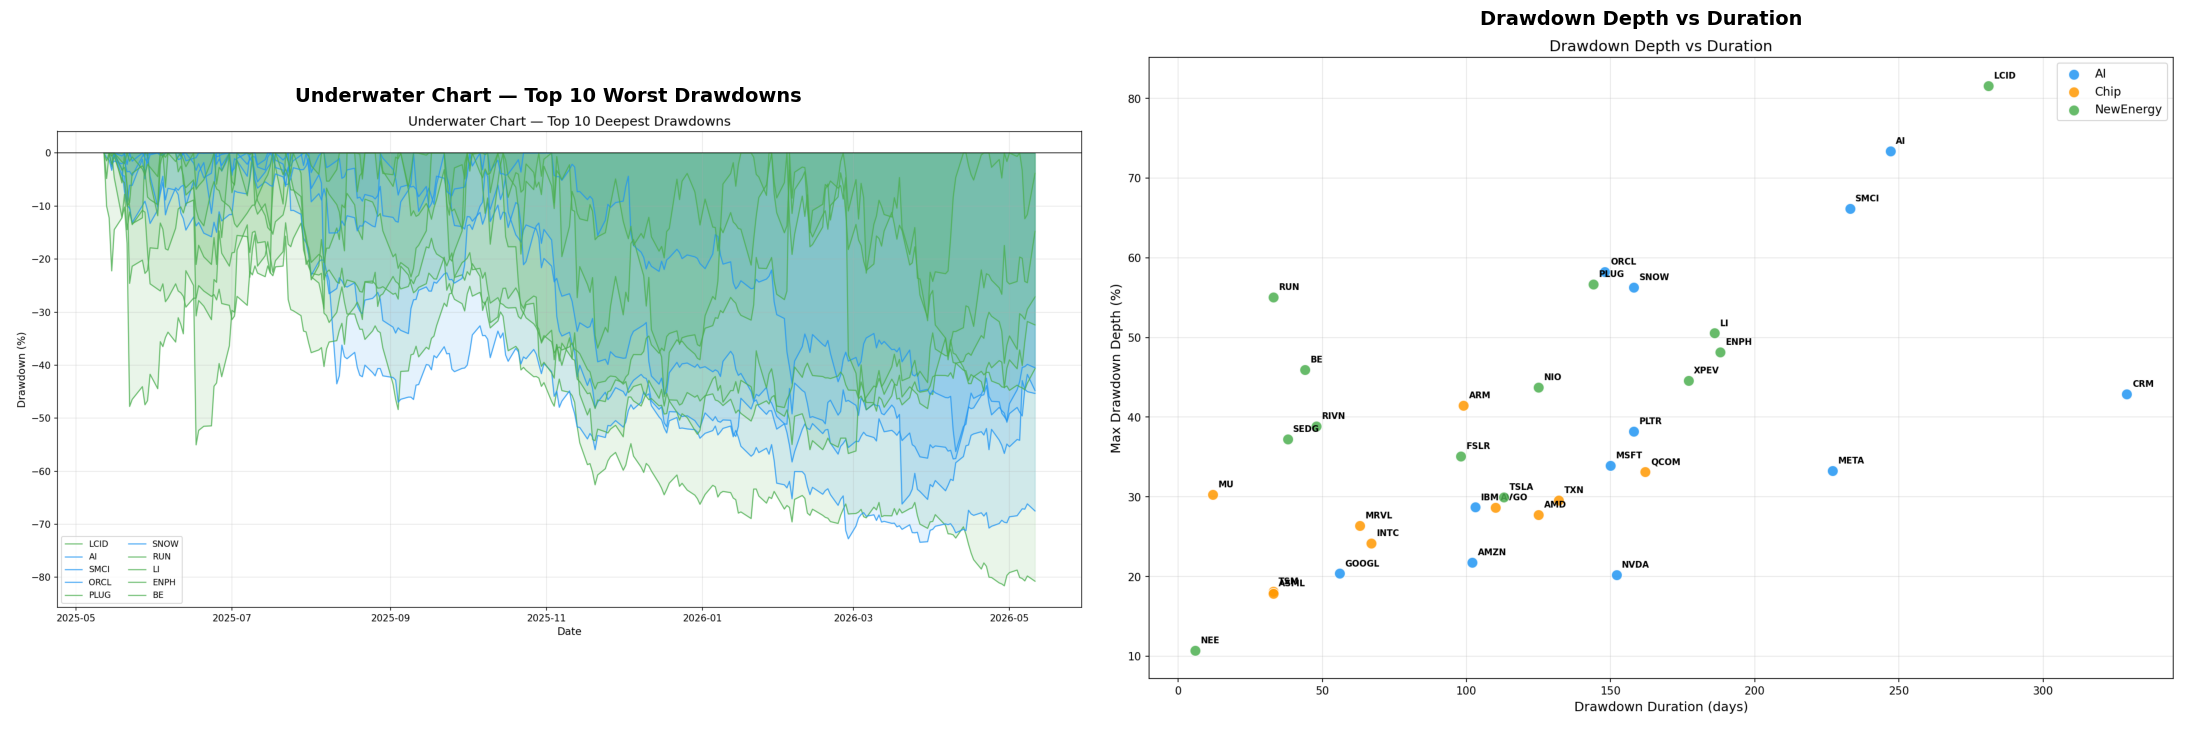

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))
ax1.imshow(mpimg.imread(str(CHART / "Part5_Risk/Step10_Drawdown/underwater_top10.png")))
ax1.set_title("Underwater Chart — Top 10 Worst Drawdowns", fontsize=14, fontweight="bold")
ax1.axis("off")
ax2.imshow(mpimg.imread(str(CHART / "Part5_Risk/Step10_Drawdown/drawdown_depth_vs_duration.png")))
ax2.set_title("Drawdown Depth vs Duration", fontsize=14, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

### <center> **Formula**

**Drawdown Time Series (Underwater Chart):**
$$DD_t = \frac{P_t - \displaystyle\max_{\tau \leq t},P_\tau}{\displaystyle\max_{\tau \leq t},P_\tau}$$
**Drawdown Duration:**
$$D_{drawdown} = t_{trough} - t_{peak} \quad \text{(days)}$$

  - $P_t$ — closing price at day $t$
  - $\max_{\tau \leq t} P_\tau$ — highest closing price from the start up to day $t$

  - $t_{trough}$ — date of the lowest point (deepest drawdown)
  - $t_{peak}$ — date of the preceding highest point

### **Findings**

1. In the graph, we have 10 most severe drawdowns, but 7 had not recovered by the end of the analysis period. It means, in this sample, once a stock drops by more than 50%, the probability of recovering within one year is relatively low.

2. The chip part experienced lower drawdowns and faster recoveries: its average maximum drawdown was **-27.7%**, with most stocks recovering within **15–78 days**. In contrast, the New Energy part had an average maximum drawdown of **-44.5%**, even with many stocks marked as **Not recovered**.

3. **MU** showed the V-shaped rebound: it declined for only **12 days** from **March 18 to March 30**, then fully recovered within **15 days**. It shows that the market(and people) had strong confidence in MU's fundamentals.

4. **LCID** is the worst: it began falling in **July 2025**, declined for **281 days**, and reached a drawdown of **-81.6%**, not recovered by the end of the analysis period.



In [14]:
dd = pd.read_csv(CHART / "Part5_Risk/Step10_Drawdown/drawdown_analysis.csv")
print("Top 10 Worst Drawdowns (by severity)")
display(dd.nsmallest(10, "Max_Drawdown%")[
    ["Ticker", "Name", "Sector", "Max_Drawdown%", "Peak_Date", "Trough_Date", "Drawdown_Days", "Recovery_Date"]
].reset_index(drop=True))

Top 10 Worst Drawdowns (by severity)


,Ticker,Name,Sector,Max_Drawdown%,Peak_Date,Trough_Date,Drawdown_Days,Recovery_Date
0,LCID,Lucid,NewEnergy,-81.60,2025-07-22,2026-04-29,281,Not recovered
1,AI,C3.ai,AI,-73.39,2025-07-23,2026-03-27,247,Not recovered
2,SMCI,Super Micro Computer,AI,-66.18,2025-07-30,2026-03-20,233,Not recovered
3,ORCL,Oracle,AI,-58.25,2025-09-10,2026-02-05,148,Not recovered
4,PLUG,Plug Power,NewEnergy,-56.66,2025-10-06,2026-02-27,144,Not recovered
5,SNOW,Snowflake,AI,-56.30,2025-11-03,2026-04-10,158,Not recovered
6,RUN,Sunrun,NewEnergy,-55.02,2025-05-15,2025-06-17,33,2025-08-15
7,LI,Li Auto,NewEnergy,-50.53,2025-07-18,2026-01-20,186,Not recovered
8,ENPH,Enphase Energy,NewEnergy,-48.17,2025-05-16,2025-11-20,188,2026-02-04
9,BE,Bloom Energy,NewEnergy,-45.94,2025-11-03,2025-12-17,44,2026-01-16


### Step 11 — Risk Metrics (VaR, Sharpe, Sortino, Calmar)

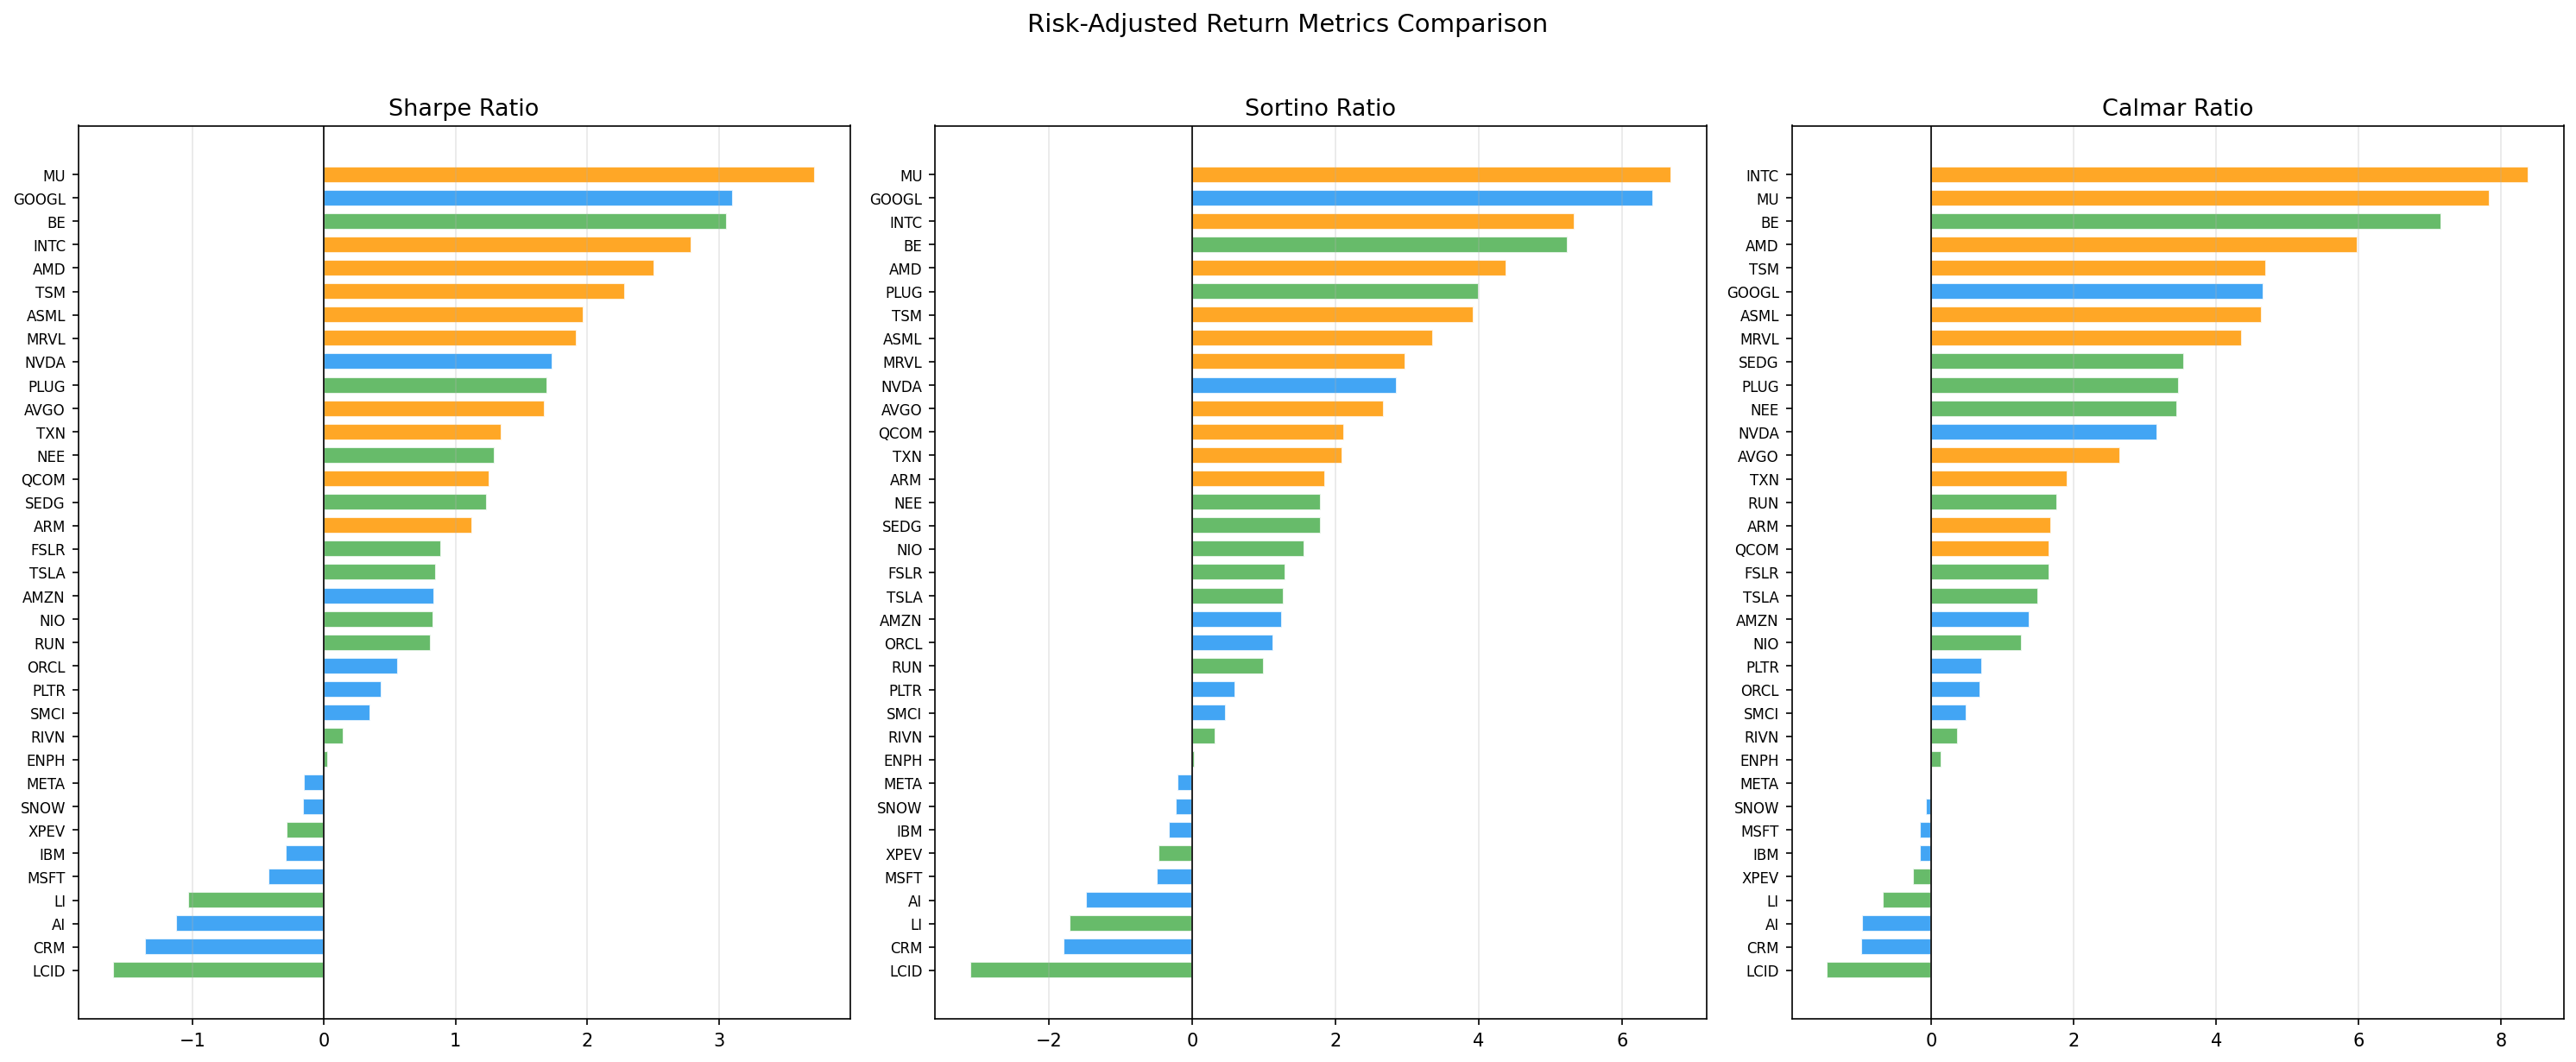

In [15]:
display(Image(str(CHART / "Part5_Risk/Step11_RiskMetrics/risk_ratios_comparison.png"), width=950))

### <center> **Formula**

**Var**:
$$VaR_{95\%} = \text{Percentile}(R_t, \ 5\%)$$
**Sortino**
$$Sortino = \frac{R_{annual} - R_f}{\sigma_{downside}}$$
**Calmar Ratio**
$$Calmar = \frac{R_{annual}}{|MaxDrawdown|}$$
  
  - $VaR_{95\%}$ — Value at Risk at 95% confidence level (the worst daily loss exceeded only 5% of the time)
  - $R_t$ — daily return at day $t$
  - $\text{Percentile}(\cdot, 5\%)$ — 5th percentile of the daily return distribution
  - $R_{annual}$ — annualized return
  - $R_f$ — risk-free rate (5%)
  - $\sigma_{downside}$ — downside deviation (standard deviation of negative returns only)
  - $|MaxDrawdown|$ — absolute value of the maximum drawdown

In [16]:
risk = pd.read_csv(CHART / "Part5_Risk/Step11_RiskMetrics/risk_metrics.csv")

print("Sector Risk Summary")
sector_risk = risk.groupby("Sector").agg({
    "Ann_Return%": "mean", "Ann_Vol%": "mean", "Sharpe": "mean",
    "Sortino": "mean", "Max_DD%": "mean", "VaR_95_Hist%": "mean", "Beta": "mean",
}).round(2)
display(sector_risk.sort_values("Sharpe", ascending=False))

print("\nTop 10 by Sharpe Ratio")
display(risk.nlargest(10, "Sharpe")[
    ["Ticker", "Name", "Sector", "Ann_Return%", "Ann_Vol%", "Sharpe", "Sortino", "Calmar", "Beta"]
].reset_index(drop=True))

Sector Risk Summary


,Ann_Return%,Ann_Vol%,Sharpe,Sortino,Max_DD%,VaR_95_Hist%,Beta
Sector,,,,,,,
Chip,114.70,50.75,2.06,3.54,-27.74,-3.93,2.10
NewEnergy,62.24,72.56,0.61,1.00,-44.47,-6.06,1.83
AI,13.60,44.40,0.30,0.68,-41.12,-4.02,1.59



Top 10 by Sharpe Ratio


,Ticker,Name,Sector,Ann_Return%,Ann_Vol%,Sharpe,Sortino,Calmar,Beta
0,MU,Micron,Chip,237.31,62.22,3.73,6.69,7.84,2.63
1,GOOGL,Google,AI,95.06,29.00,3.11,6.43,4.67,1.29
2,BE,Bloom Energy,NewEnergy,328.87,105.89,3.06,5.24,7.16,3.74
3,INTC,Intel,Chip,202.59,70.88,2.79,5.34,8.38,2.37
4,AMD,AMD,Chip,166.01,64.11,2.51,4.38,5.98,2.65
5,TSM,TSMC,Chip,85.26,35.10,2.29,3.93,4.70,1.91
6,ASML,ASML,Chip,82.78,39.45,1.97,3.36,4.64,1.99
7,MRVL,Marvell,Chip,115.00,57.40,1.92,2.98,4.36,2.26
8,NVDA,NVIDIA,AI,64.15,33.92,1.74,2.85,3.17,1.76
9,PLUG,Plug Power,NewEnergy,197.19,112.81,1.70,4.00,3.48,2.67



**Chip sector leads on every risk-adjusted metric.** NewEnergy has the worst daily VaR (-6.1%); the highest tail-risk stocks are all NewEnergy (RUN -25.8%, ENPH -14.7%).
>Chip sector represents truly high-quality returns, continuing to outperform other sectors even after adjusting for risk.


---
## Part 6: Portfolio Optimization

### Step 12 — Efficient Frontier

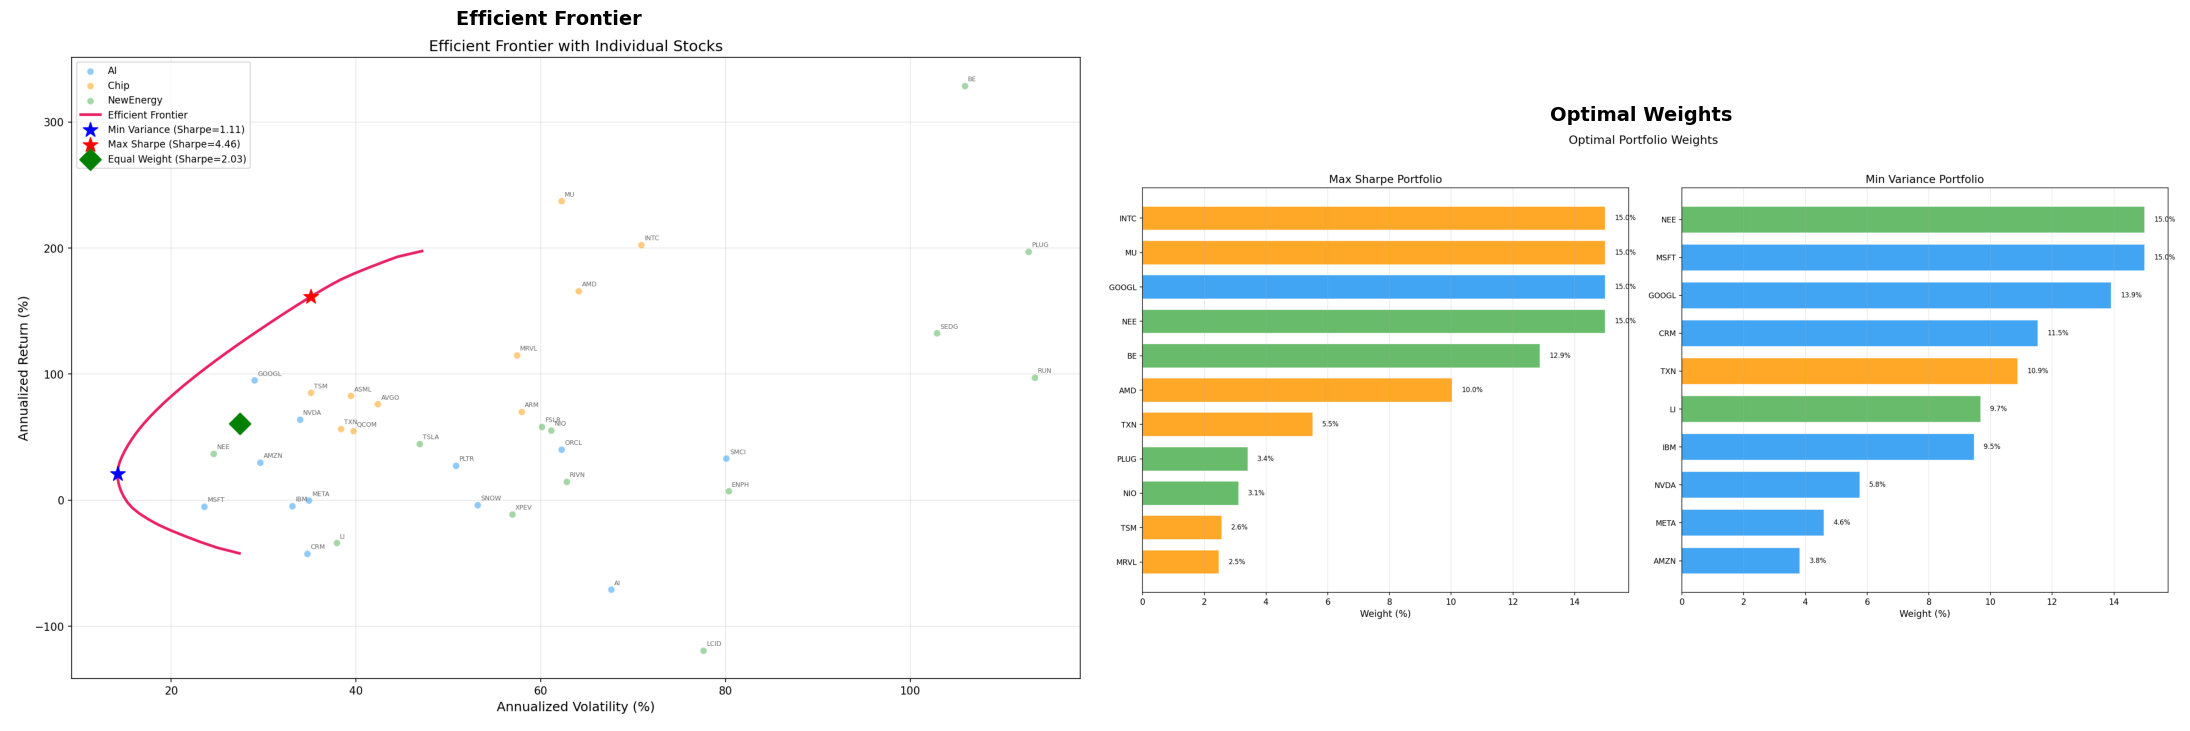

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 8))
ax1.imshow(mpimg.imread(str(CHART / "Part6_Portfolio/Step12_EfficientFrontier/efficient_frontier.png")))
ax1.set_title("Efficient Frontier", fontsize=14, fontweight="bold")
ax1.axis("off")
ax2.imshow(mpimg.imread(str(CHART / "Part6_Portfolio/Step12_EfficientFrontier/optimal_weights.png")))
ax2.set_title("Optimal Weights", fontsize=14, fontweight="bold")
ax2.axis("off")
plt.tight_layout()
plt.show()

### <center> **Formula**

**max sharp**:
$$\max_{\mathbf{w}} \frac{R_p - R_f}{\sigma_p} = \frac{\mathbf{w}^T \mathbf{\mu} - R_f}{\sqrt{\mathbf{w}^T \Sigma
  \mathbf{w}}}$$
**min variance**:
  $$\min_{\mathbf{w}} \ \sigma_p^2 = \mathbf{w}^T \Sigma \mathbf{w}$$
**Constraints:**

  $$\sum_{i=1}^{n} w_i = 1 \quad \text{(fully invested, weights sum to 1)}$$

  $$0 \leq w_i \leq 0.15 \quad \text{(long-only, max 15\% per stock)}$$

  The 15% cap prevents excessive concentration in any single stock. In the results, GOOGL, INTC, MU, and NEE all hit the
   15% cap.
- $\mathbf{w}$ — weight vector (allocation per stock)
- $\mathbf{\mu}$ — expected return vector for each stock
- $R_f$ — risk-free rate (5%)
- $\Sigma$ — covariance matrix (captures co-movement between stocks)
- $n$ — total number of stocks (35)
- $w_i$ — weight of the $i$-th stock

**Solver:**

  Solved numerically using **scipy.optimize.minimize.py** with the SLSQP (Sequential Least Squares Programming) algorithm. 

In [18]:
weights = pd.read_csv(CHART / "Part6_Portfolio/Step12_EfficientFrontier/optimal_weights.csv")

print("Max Sharpe Portfolio — Core Holdings (weight > 1%)")
ms = weights[weights["MaxSharpe_Weight%"] > 1].sort_values("MaxSharpe_Weight%", ascending=False)
display(ms[["Ticker", "Name", "Sector", "MaxSharpe_Weight%"]].reset_index(drop=True))

print("\nMin Variance Portfolio — Core Holdings (weight > 1%)")
mv = weights[weights["MinVar_Weight%"] > 1].sort_values("MinVar_Weight%", ascending=False)
display(mv[["Ticker", "Name", "Sector", "MinVar_Weight%"]].reset_index(drop=True))

print("\nSector Allocation Comparison")
alloc = []
for label, col in [("Max Sharpe", "MaxSharpe_Weight%"), ("Min Variance", "MinVar_Weight%"), ("Equal Weight", "EqualWeight%")]:
    row = {"Portfolio": label}
    for sector in ["AI", "Chip", "NewEnergy"]:
        pct = weights[weights["Sector"] == sector][col].sum()
        row[sector] = f"{pct:.1f}%"
    alloc.append(row)
display(pd.DataFrame(alloc).set_index("Portfolio"))

Max Sharpe Portfolio — Core Holdings (weight > 1%)


,Ticker,Name,Sector,MaxSharpe_Weight%
0,GOOGL,Google,AI,15.00
1,INTC,Intel,Chip,15.00
2,MU,Micron,Chip,15.00
3,NEE,NextEra Energy,NewEnergy,15.00
4,BE,Bloom Energy,NewEnergy,12.88
5,AMD,AMD,Chip,10.03
6,TXN,Texas Instruments,Chip,5.51
7,PLUG,Plug Power,NewEnergy,3.41
8,NIO,NIO,NewEnergy,3.12
9,TSM,TSMC,Chip,2.56



Min Variance Portfolio — Core Holdings (weight > 1%)


,Ticker,Name,Sector,MinVar_Weight%
0,MSFT,Microsoft,AI,15.00
1,NEE,NextEra Energy,NewEnergy,15.00
2,GOOGL,Google,AI,13.91
3,CRM,Salesforce,AI,11.54
4,TXN,Texas Instruments,Chip,10.88
5,LI,Li Auto,NewEnergy,9.69
6,IBM,IBM,AI,9.48
7,NVDA,NVIDIA,AI,5.77
8,META,Meta,AI,4.60
9,AMZN,Amazon,AI,3.83



Sector Allocation Comparison


,AI,Chip,NewEnergy
Portfolio,,,
Max Sharpe,15.0%,50.6%,34.4%
Min Variance,64.1%,11.2%,24.7%
Equal Weight,34.3%,28.6%,37.2%


### Step 13 — Portfolio Backtesting

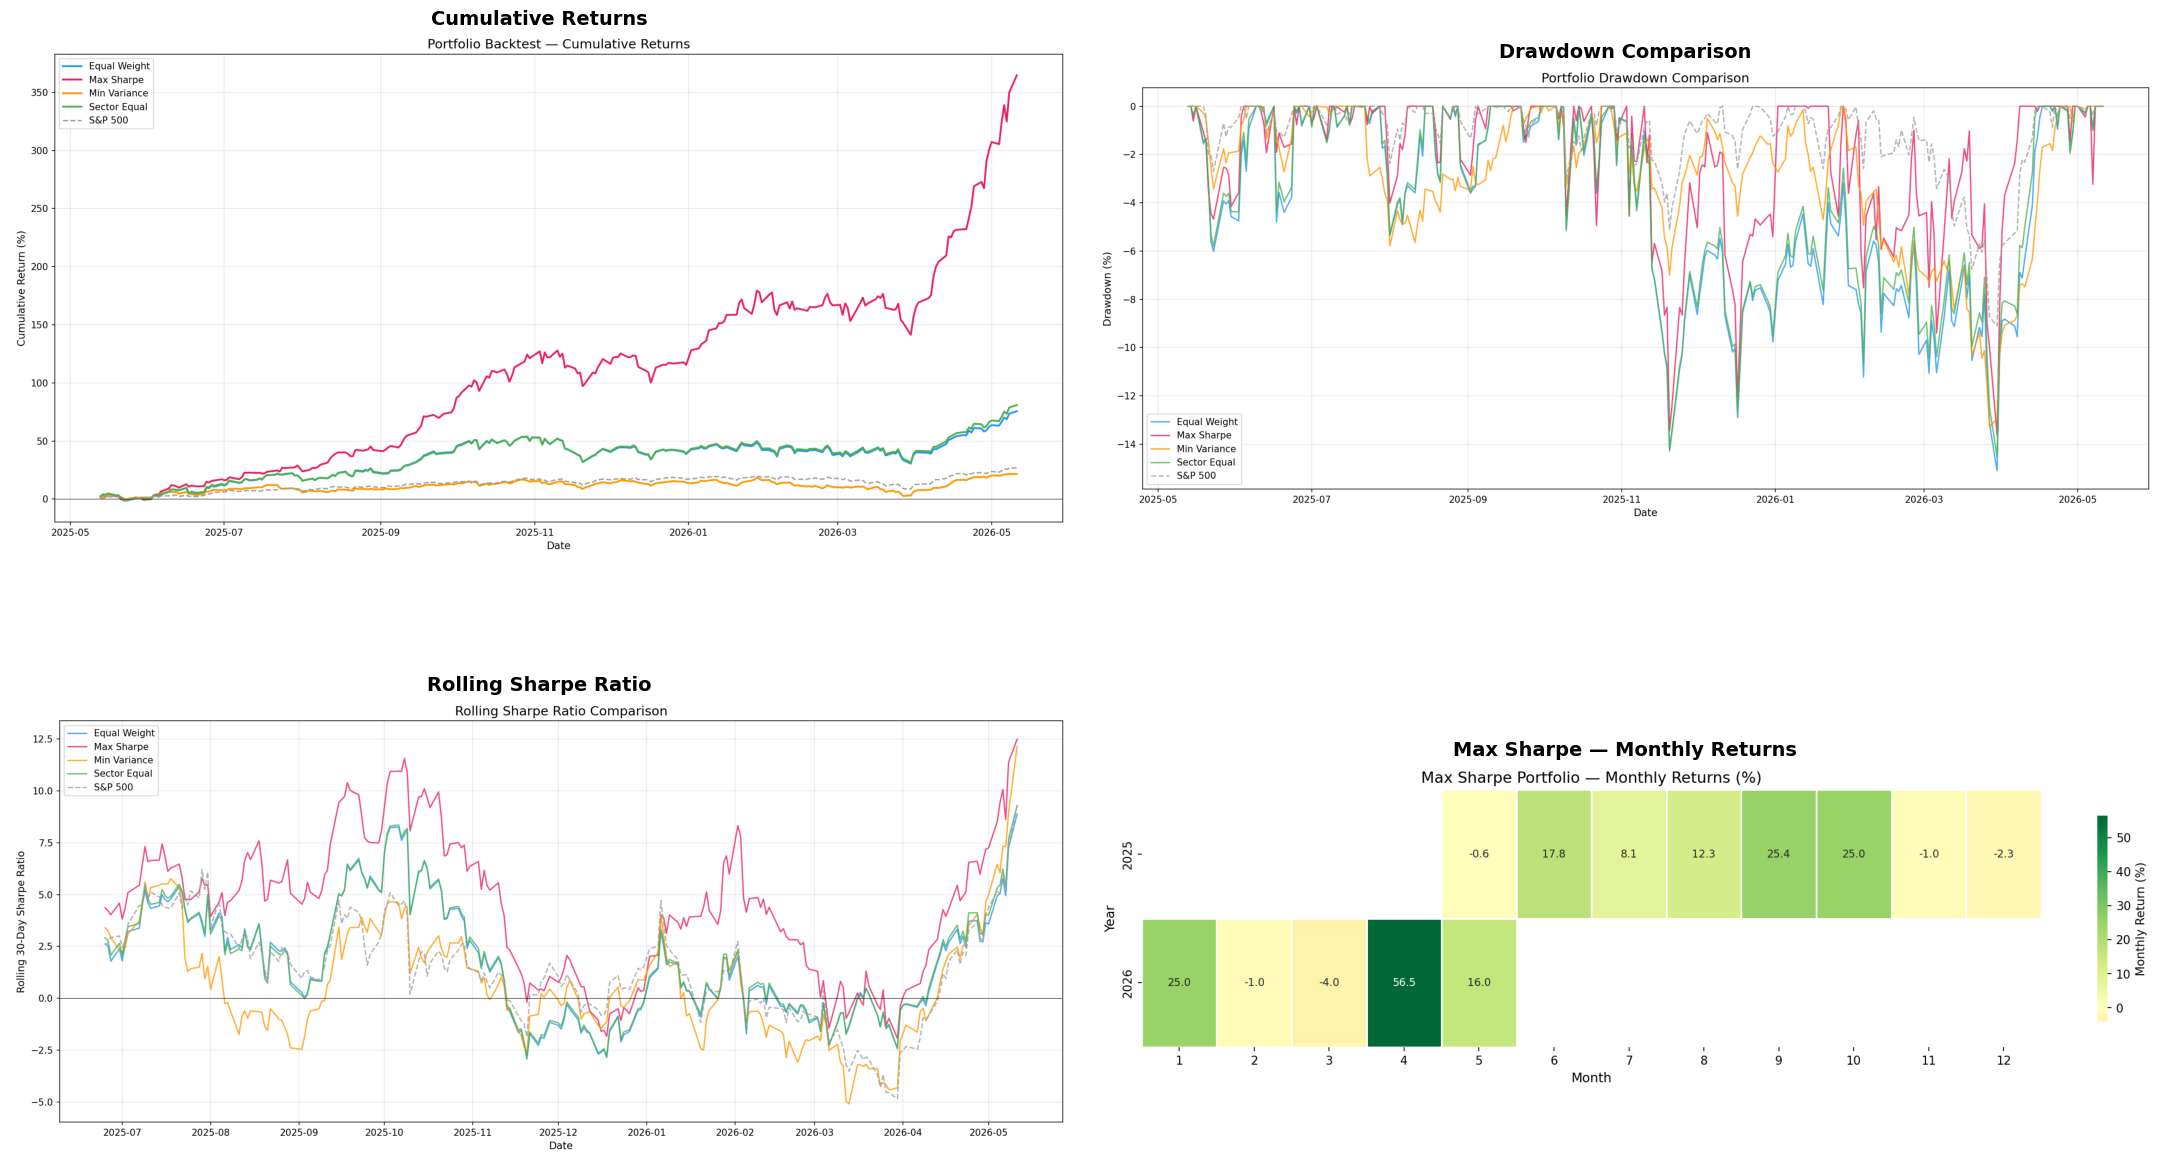

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(22, 14))
imgs = [
    (CHART / "Part6_Portfolio/Step13_Backtest/cumulative_returns.png", "Cumulative Returns"),
    (CHART / "Part6_Portfolio/Step13_Backtest/drawdown_comparison.png", "Drawdown Comparison"),
    (CHART / "Part6_Portfolio/Step13_Backtest/rolling_sharpe.png", "Rolling Sharpe Ratio"),
    (CHART / "Part6_Portfolio/Step13_Backtest/monthly_returns_heatmap.png", "Max Sharpe — Monthly Returns"),
]
for ax, (path, title) in zip(axes.flat, imgs):
    ax.imshow(mpimg.imread(str(path)))
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")
plt.tight_layout(pad=2)
plt.show()

### <center> **Formula**

**Cumulative Return**
  $$R_{cum,t} = \prod_{s=1}^{t}(1 + r_s) - 1$$
  - $r_s$ — daily portfolio return at day $s$ 
  - $R_{cum,t}$ — cumulative return up to day $t$ 

**Win Rate"**
$$Win\% = \frac{\text{days where } r_t > 0}{N} \times 100%$$

**Daily Portfolio Return** 

$$r_{p,t} = \sum_{i=1}^{n} w_i \cdot r_{i,t}$$

  - $w_i$ — fixed weight of stock $i$ (no rebalancing)
  - $r_{i,t}$ — daily return of stock $i$ at day $t$ 


In [20]:
print("Portfolio Performance Comparison")
portfolio_perf = pd.read_csv(CHART / "Part6_Portfolio/Step13_Backtest/portfolio_performance.csv")
display(portfolio_perf.set_index("Portfolio"))

Portfolio Performance Comparison


,Total_Return%,Ann_Return%,Ann_Vol%,Sharpe,Sortino,Max_DD%,Calmar,Win_Rate%
Portfolio,,,,,,,,
Equal Weight,75.59,60.55,27.42,2.03,3.14,-15.11,4.01,56.4
Max Sharpe,364.75,161.45,35.10,4.46,6.82,-13.61,11.86,63.6
Min Variance,21.56,20.69,14.18,1.11,1.69,-13.29,1.56,58.0
Sector Equal,80.90,63.51,27.24,2.15,3.34,-14.54,4.37,56.0
S&P 500,26.84,24.71,12.09,1.63,2.34,-9.10,2.72,57.2


---
# Conclusion

---

## Sector Performance Overview

| Sector | Avg Return | Sharpe Ratio | Avg Alpha | Key Message |
|---|---:|---:|---:|---|
| **Semiconductors** | **+225.5%** | **2.17** | **+62.8%** | Clear winner |
| **AI** | **+13.0%** | Weakest | **-24.2%** | Strong hype, weak returns |
| **New Energy** | **+142.9%** | High risk | Mixed | Driven by extreme outliers |

---

## 1. Semiconductors: The Winner

The **semiconductor sector** was the strongest performer, led by:

- **MU: +764%**
- **INTC: +484%**
- **AMD: +324%**

These stocks not only delivered extraordinary returns, but also performed well after adjusting for risk. Their **Calmar ratios were all above 5.0**, and most drawdowns recovered within **15–78 days**.

This suggests that the market viewed the AI revolution primarily as a **hardware and infrastructure revolution**. Companies that manufacture chips and core infrastructure captured the largest share of value.

---

## 2. AI Software: Strong Narrative, Weak Stock Performance

Although AI technology developed rapidly, AI-related software stocks performed surprisingly poorly.

The AI sector had:

- Average return of only **+13.0%**
- S&P 500 return of **+26.8%**
- Average Alpha of **-24.2%**

Major companies such as **MSFT (-7.4%)**, **META (-6.1%)**, and **CRM (-38.1%)** all posted losses.

This indicates that the market remains skeptical about whether AI software companies can generate enough revenue to justify their massive infrastructure investment.

---

## 3. New Energy: Extreme Divergence

The **new energy sector** showed the strongest internal divergence.

Although its average return was **+142.9%**, this result was heavily driven by **Bloom Energy (BE, +1,401%)**. After removing BE, the sector’s average return dropped to only **+38.0%**.

The sector also had the highest risk:

- Volatility: **72.6%**
- Average drawdown: **-44.5%**
- Daily VaR 95%: **-6.1%**

This shows that new energy is more of a **stock-picking market** than a sector-wide trend.

---

## 4. Correlation and Market Structure

Correlation analysis shows that **new energy is largely independent** from AI and semiconductors, with cross-sector correlations around **0.12–0.18**.

This makes new energy a useful **portfolio diversification tool**, even though the sector itself does not provide stable returns.

Within the technology ecosystem, **TSM** acts as the key correlation hub between AI and chip stocks. Information appears to flow along the real supply chain, from AI platform companies such as **NVDA** and **PLTR** to semiconductor manufacturers such as **TSM**, **INTC**, and **ASML**, with a lag of about **1–2 days**.

---

## Outlook

As long as AI infrastructure investment remains the dominant market theme, the semiconductor sector is likely to continue leading. However, its high Beta, averaging **2.10**, also means that losses may be amplified during market pullbacks.

And I think AI company or AI tech is now facing a critical turning point. It must prove that AI capabilities can be monetized at scale; otherwise, the sector may continue to underperform.

For New energy, it remains highly dependent on individual company catalysts, such as hydrogen energy, energy storage, and EV adoption. Its low correlation with other sectors confirms its value for diversification, but not necessarily for stable return generation.

Finally, besides these industries, other AI-related industries, such as **medical AI infrastructure** and **robotic intelligence systems**, may also have great prospects in the future AI era.

---

*Tech stack: pandas / numpy / matplotlib / seaborn / scipy / yfinance*